# Suggesting the Expense Type for Department for Transport spend lines

**Patrick Gilliland**

**Question.** Can a model trained on the Department for Transport's past ledger lines suggest the right Expense Type for a new line over £25,000, and what share of lines could it code confidently enough to leave the rest to a person?

**Task 1: the problem and the dataset.** Every payment line a finance team posts carries an account code, which in this data is the `Expense Type`. The problem is to suggest that code for a new line from the other fields on the line, such as the supplier and the item text. In accounting terms this is general ledger account classification: assigning an account code to each posting line. The task is supervised learning (classification), and it is multi-class, because `Expense Type` holds many labels. The dataset is [Spend over £25,000 in the Department for Transport and its arms-length bodies](https://www.data.gov.uk/dataset/804be0c6-ae01-4899-bbb9-2317dff1a4f9/financial-transactions-data-dft), which the Department for Transport (DfT) lists on data.gov.uk, as one CSV file a month hosted on GOV.UK. I use the 48 months from April 2022 to March 2026. `build_dataset.py` stacks the original monthly files in `dft_originals/` into `dft_spend_over_25k_2022-04_to_2026-03.csv`, beside this notebook, without changing any value: it only trims the column names and maps five files' variant names to one set. Contains public sector information licensed under the Open Government Licence v3.0.

**Report.** The Machine Learning Analysis Report is one PDF under the two names the brief uses: `module_summary.pdf`, and an identical copy named `Machine_Learning_Analysis_Report.pdf`.

## Data preparation

### Setup

In [1]:
import hashlib
import os
import platform
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, top_k_accuracy_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    OrdinalEncoder,
    StandardScaler,
)

# I show every column and whole cell text, up to 500 rows so the anomaly
# listings appear in full, and figures with thousands separators and no
# scientific notation: two decimal places, or three for a share below 1, so
# metrics that differ in the third place can be told apart.
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 500)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)
pd.set_option(
    "display.float_format",
    lambda x: f"{x:,.3f}" if 0 < abs(x) < 1 else f"{x:,.2f}",
)

# Every step below that draws at random takes this seed, so a rerun gives the
# same numbers.
SEED = 42

print(f"Python {platform.python_version()}")
print(f"NumPy {np.__version__}")
print(f"pandas {pd.__version__}")
print(f"scikit-learn {sklearn.__version__}")
print(f"Matplotlib {matplotlib.__version__}")
print(f"Seaborn {sns.__version__}")
print(f"Random seed: {SEED}")
print(f"CPU cores: {os.cpu_count()}")

Python 3.12.3
NumPy 2.5.3
pandas 3.0.6
scikit-learn 1.9.1
Matplotlib 3.11.2
Seaborn 0.13.2
Random seed: 42
CPU cores: 24


**Hardware.** I run everything on the CPU, with no GPU. The models are scikit-learn's, and the whole file fits in memory, so I load it in one go. Neither model takes an `n_jobs` setting in scikit-learn 1.9.1: HistGradientBoosting spreads its work over every core by itself, and logistic regression's `n_jobs` has no effect for this solver, so I leave it unset.

### Task 2: Load and inspect the dataset

In [2]:
DATA = Path("dft_spend_over_25k_2022-04_to_2026-03.csv")
EXPECTED_SHA256 = (
    "3d9d7f911ef00f9394c07077ebb1ec161efbeb7f3073824c801a662aac212bd4"
)

if not DATA.exists():
    raise FileNotFoundError(
        f"{DATA} is not beside this notebook. Build it from the 48 original "
        "monthly files in dft_originals/ with: python build_dataset.py"
    )
digest = hashlib.sha256(DATA.read_bytes()).hexdigest()
print(f"File: {DATA}, {DATA.stat().st_size:,} bytes")
print(f"SHA-256: {digest}")
# Every figure below comes from this exact file, so I stop rather than
# analyse a different one.
if digest != EXPECTED_SHA256:
    raise ValueError(
        f"{DATA} is not the file build_dataset.py writes from the 48 original "
        "files. Rebuild it with: python build_dataset.py"
    )
print(
    "It matches the file build_dataset.py writes from the 48 original files."
)

# I read every cell as the text DfT published. The amounts carry a pound sign
# and commas, and by default pandas would turn text such as "#N/A" into a
# blank, so nothing is converted on load.
df = pd.read_csv(DATA, dtype=str, keep_default_na=False)
print(f"Loaded: {len(df):,} rows, {df.shape[1]} columns")

File: dft_spend_over_25k_2022-04_to_2026-03.csv, 25,396,696 bytes
SHA-256: 3d9d7f911ef00f9394c07077ebb1ec161efbeb7f3073824c801a662aac212bd4
It matches the file build_dataset.py writes from the 48 original files.
Loaded: 126,346 rows, 11 columns


In [3]:
df.head()

,Department Family,Entity,Date,Expense Type,Expense Area,Supplier,Transaction No,Item Text,£,Postal Code,source_file
0,Department for Transport,Department for Transport,05/04/2022,Grt Aid to NDPBs,DG Rail Strategy and Services Group,NETWORK RAIL ISTRE (CAPITAL GRANTS),2000000612,NR GRANT APRIL 2 SR 9000946295,"£418,408,000.00",NW1 2DN,dft_2022-04.csv
1,Department for Transport,Department for Transport,29/04/2022,Grt Aid to NDPBs,"DG Roads, Places and Environment",National Highways Limited,2000003150,Grant in Aid NH for May 2022,"£298,000,000.00",B1 1RN,dft_2022-04.csv
2,Department for Transport,Department for Transport,29/04/2022,CurrGrtOth to NDPBs,DG Rail Strategy and Services Group,NETWORK RAIL ISTRE (CAPITAL GRANTS),2000003127,NR Grant - DUE 03/05/2022 - SR 9000953144,"£151,086,319.00",NW1 2DN,dft_2022-04.csv
3,Department for Transport,High Speed Two (HS2) Limited,07/04/2022,AUC - Phase 1,000000 AUC - Phase 1,BALFOUR BEATTY VINCI JV - HS2 (N2),#,MWCC Stage One TP,"£135,660,641.62",#,dft_2022-04.csv
4,Department for Transport,Department for Transport,05/04/2022,Cap Grt NDPBs & CG,DG Rail Strategy and Services Group,NETWORK RAIL ISTRE (CAPITAL GRANTS),2000000612,NR GRANT APRIL 2 SR 9000946295,"£117,640,000.00",NW1 2DN,dft_2022-04.csv


In [4]:
published = [name for name in df.columns if name != "source_file"]
stripped = df.apply(lambda column: column.str.strip())
blank_row = stripped[published].eq("").all(axis=1)
blank_files = ", ".join(df.loc[blank_row, "source_file"].unique())
print(
    f"Rows: {len(df):,}, of which {blank_row.sum():,} have every published "
    f"cell blank, all from {blank_files}"
)

# The publisher marks a missing value with "#", and a few cells hold the
# spreadsheet error "#N/A", so I count those beside the truly blank cells.
column_check = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "blank": stripped.eq("").sum(),
        '"#"': stripped.eq("#").sum(),
        '"#N/A" or "N/A"': stripped.isin(["#N/A", "N/A"]).sum(),
        "spaces at either end": df.ne(stripped).sum(),
        "distinct values": df.where(stripped.ne("")).nunique(),
    }
)
column_check

Rows: 126,346, of which 657 have every published cell blank, all from dft_2022-05.csv


,dtype,blank,"""#""","""#N/A"" or ""N/A""",spaces at either end,distinct values
Department Family,str,657,0,0,137,3
Entity,str,657,0,0,1260,15
Date,str,657,0,0,1,1387
Expense Type,str,657,0,0,666,1054
Expense Area,str,657,0,4,756,976
Supplier,str,657,0,0,381,4015
Transaction No,str,657,10192,2,0,97175
Item Text,str,657,16139,57,1977,20231
£,str,657,0,0,50587,104351
Postal Code,str,657,16978,0,210,2791


In [5]:
def parse_fields(frame, amount="£", date="Date", source="source_file"):
    """Return a copy of frame with the amount, date and month as typed columns.

    Three columns are added. amount is the amount in pounds as a float,
    read from text such as " £1,234.50 ". date is the payment date, read as
    day/month/year, or as day.month.year where the file uses dots. month is
    the month of the file the row came from, "YYYY-MM", taken from the
    source file's name. A value that cannot be read is left blank (NaN or
    NaT). frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        The rows as published, every column text.
    amount, date, source : str
        The names of the amount, date and source file columns.

    Returns
    -------
    pandas.DataFrame
        frame's columns unchanged, then amount, date and month.
    """
    out = frame.copy()
    money = frame[amount].str.strip().str.replace("£", "", regex=False)
    money = money.str.replace(",", "", regex=False)
    out["amount"] = pd.to_numeric(money, errors="coerce").astype(float)
    text = frame[date].str.strip()
    slashes = pd.to_datetime(text, format="%d/%m/%Y", errors="coerce")
    dots = pd.to_datetime(text, format="%d.%m.%Y", errors="coerce")
    out["date"] = slashes.fillna(dots)
    out["month"] = frame[source].str.extract(r"(\d{4}-\d{2})", expand=False)
    return out

In [6]:
df = parse_fields(df)
content = ~blank_row
written = df.loc[content, "Date"]
slash_form = written.str.fullmatch(r"\d{2}/\d{2}/\d{4}")
dot_form = written.str.fullmatch(r"\d{2}\.\d{2}\.\d{4}")
spaced = written.ne(written.str.strip())
print(
    f"Amounts read: {df.loc[content, 'amount'].notna().sum():,} of "
    f"{content.sum():,} lines with content"
)
print(
    f"Dates read: {df.loc[content, 'date'].notna().sum():,} of "
    f"{content.sum():,}; {slash_form.sum():,} written dd/mm/yyyy, "
    f"{dot_form.sum():,} written dd.mm.yyyy, {spaced.sum():,} with spaces "
    "round it"
)
months = df["month"]
print(f"Months: {months.nunique()}, {months.min()} to {months.max()}")
print(f"Published total: £{df['amount'].sum():,.2f}")
print(
    f"Smallest line: £{df['amount'].min():,.2f}; "
    f"largest: £{df['amount'].max():,.2f}"
)
df[["amount", "date", "month"]].dtypes

Amounts read: 125,689 of 125,689 lines with content
Dates read: 125,689 of 125,689; 125,660 written dd/mm/yyyy, 28 written dd.mm.yyyy, 1 with spaces round it
Months: 48, 2022-04 to 2026-03
Published total: £177,111,208,418.51
Smallest line: £25,000.00; largest: £786,575,788.00


amount           float64
date      datetime64[us]
month                str
dtype: object

**What loaded.** The file loads as 126,346 rows and 11 columns: the ten columns DfT publishes and `source_file`, which names the monthly file each row came from. I read every cell as text, so every column loads as text. `parse_fields` then adds the amount as a number, the date as a date and the file's month. Every one of the 125,689 lines with content has an amount and a date I can read, across 48 months.

**Obvious data quality issues.**

- 657 rows are blank in every published column, all from the May 2022 file. The build keeps them, so the combined file holds every row DfT published.
- The amount is text with a pound sign and commas, and 50,587 amount cells have spaces round them. Every amount reads, from £25,000.00 to £786,575,788.00, so no line is published as a credit, with a minus sign.
- The date is text too. 125,660 lines write it dd/mm/yyyy, 28 use dots and 1 has spaces round it. `parse_fields` reads all three forms.
- The publisher writes "#" for a missing value: in 10,192 transaction numbers, 16,139 item texts and 16,978 postcodes. The spreadsheet error "#N/A" sits in 4 Expense Area cells and 57 item texts, and 2 transaction numbers read "N/A". I read the file with `keep_default_na=False`, so pandas cannot turn any of these into a blank without my knowing.
- Names are not always written one way. Department Family has 3 spellings for one department, Entity has 15 values, with spaces round 1,260 of its cells, and Expense Type has 1,054 labels, some of which differ only in case, spacing or punctuation.

I list each of these, and the other anomalies I found, with its count and value in the anomaly list below, before anything is cleaned.

### The anomaly list

Before anything is cleaned, I list every anomaly I could find in the 48 months, kind by kind. For each kind the anomaly list gives the lines it touches, their value, and the published total with and without them. Each kind also has my proposed treatment, flag, keep or exclude, and the ruling on it. Nothing is removed here: Task 3 applies the rulings, keeps every raw row and gives any excluded line its reason. First come the listings the list draws on: the original files, the time-ordered hold-out, the label variants, the truncation pairs and the 2025 National Highways labels.

In [7]:
def file_anomalies(manifest, schema, usual_encoding="cp1252"):
    """Return the original files whose encoding or header is not the usual one.

    A file is listed when its encoding is not usual_encoding, or when a
    column in its header is named differently from schema at the same
    position. manifest is not changed.

    Parameters
    ----------
    manifest : pandas.DataFrame
        One row per original file: file, month, encoding, rows (text, as
        the manifest stores it) and header, a tuple of its trimmed column
        names.
    schema : list of str
        The column names the build maps every header to.
    usual_encoding : str, default "cp1252"
        The encoding most of the files use.

    Returns
    -------
    pandas.DataFrame
        Indexed by file: month, encoding, rows as a number, and the columns
        named differently, each as '"published name" for "schema name"',
        or "" when the header is the usual one.
    """
    renamed = manifest["header"].map(
        lambda header: "; ".join(
            f'"{name}" for "{wanted}"'
            for name, wanted in zip(header, schema)
            if name != wanted
        )
    )
    out = manifest[["file", "month", "encoding"]].assign(
        rows=manifest["rows"].astype(int),
        **{"columns named differently": renamed},
    )
    odd = (out["encoding"] != usual_encoding) | (renamed != "")
    return out[odd].set_index("file")

In [8]:
# The build reads each original with the encoding its manifest gives, and
# maps each header to one set of column names. I read both off the
# originals here, so the files that needed either are shown, not assumed.
ORIGINALS = Path("dft_originals")
manifest = pd.read_csv(ORIGINALS / "MANIFEST.csv", dtype=str)
manifest["header"] = [
    tuple(
        name.strip()
        for name in pd.read_csv(
            ORIGINALS / row.file, encoding=row.encoding, nrows=0
        ).columns
    )
    for row in manifest.itertuples()
]
file_check = file_anomalies(manifest, schema=published)
cp850_files = list(file_check.index[file_check["encoding"] == "cp850"])
renamed = file_check["columns named differently"] != ""
drift_files = list(file_check.index[renamed])
print(
    f"Original files: {len(manifest)}; not cp1252: "
    f"{(file_check['encoding'] != 'cp1252').sum()}; with a column named "
    f"differently: {len(drift_files)}"
)
file_check

Original files: 48; not cp1252: 5; with a column named differently: 5


,month,encoding,rows,columns named differently
file,,,,
dft_2022-05.csv,2022-05,cp1252,3271,"""Expense Area rev"" for ""Expense Area"""
dft_2022-08.csv,2022-08,cp1252,2232,"""Expense Area rev"" for ""Expense Area"""
dft_2023-04.csv,2023-04,cp850,2879,"""Departmental Family"" for ""Department Family"""
dft_2023-07.csv,2023-07,cp850,2842,
dft_2023-08.csv,2023-08,cp850,2596,
dft_2024-03.csv,2024-03,cp1252,3515,"""Transaction Number"" for ""Transaction No"""
dft_2025-01.csv,2025-01,utf-8-sig,2556,
dft_2025-02.csv,2025-02,utf-8-sig,2586,
dft_2025-07.csv,2025-07,cp1252,2586,"""Departmental Family"" for ""Department Family"""


**The original files.** Of the 48 original files, 5 are not cp1252. January and February 2025 are UTF-8 and start with a byte-order mark. April, July and August 2023 store the pound sign as the single byte 0x9C, which cp850 reads as "£", so the build reads those 3 files as cp850. Separately, 5 files name a column differently, such as "Expense Area rev" in May and August 2022, and the build maps each one to the usual name. Neither changes a published value, so I propose to keep the lines from these files as they are.

In [9]:
def assign_split(
    frame, month="month", training_end="2025-06", validation_end="2025-09"
):
    """Return the time-ordered split each row falls in, from its month.

    A row is in training up to and including training_end, in validation
    up to and including validation_end, and in test after that. Months are
    "YYYY-MM" text, which sorts in time order. frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        Rows with a month column.
    month : str, default "month"
        The month column.
    training_end, validation_end : str
        The last month of training and of validation.

    Returns
    -------
    pandas.Series
        "training", "validation" or "test" on frame's index, named split.
    """
    months = frame[month]
    split = np.where(
        months <= training_end,
        "training",
        np.where(months <= validation_end, "validation", "test"),
    )
    return pd.Series(split, index=frame.index, name="split")

In [10]:
df["split"] = assign_split(df)
lines = df[content]
for name in ("training", "validation", "test"):
    in_split = lines.loc[lines["split"] == name, "month"]
    print(
        f"{name}: {in_split.min()} to {in_split.max()}, "
        f"{in_split.nunique()} months, {len(in_split):,} lines"
    )

training: 2022-04 to 2025-06, 39 months, 102,081 lines
validation: 2025-07 to 2025-09, 3 months, 7,291 lines
test: 2025-10 to 2026-03, 6 months, 16,317 lines


In [11]:
def label_variants(frame, column="Expense Type"):
    """Return every label that is another spelling of a commoner label.

    Two labels are spellings of one label when they match once case and
    every character that is not a letter or a digit are ignored. In each
    group the spelling with the most lines is the commonest, and a tie goes
    to the spelling that sorts first. Every other spelling is listed with
    the kind of difference, the first of these that applies:

    - spaces: it matches once runs of spaces are closed up and the ends
      trimmed;
    - case: it then matches ignoring case;
    - dash: it then matches once each en dash, em dash or "?" is read as a
      hyphen;
    - separator: any other difference, such as "/" for "-".

    Blank labels are left out. frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per line.
    column : str, default "Expense Type"
        The label column.

    Returns
    -------
    pandas.DataFrame
        One row per spelling that is not the commonest: label, commonest
        spelling, kind, lines and lines in commonest. Sorted by kind in the
        order above, then by lines, most first.
    """
    labels = frame[column]
    counts = labels[labels.str.strip() != ""].value_counts()
    table = pd.DataFrame({"label": counts.index, "lines": counts.to_numpy()})
    table = table.sort_values(["lines", "label"], ascending=[False, True])
    table["key"] = table["label"].str.casefold()
    table["key"] = table["key"].str.replace(r"[^a-z0-9]", "", regex=True)
    group = table.groupby("key")
    table["commonest spelling"] = group["label"].transform("first")
    table["lines in commonest"] = group["lines"].transform("first")
    out = table[table["label"] != table["commonest spelling"]].copy()

    label = out["label"]
    best = out["commonest spelling"]
    as_hyphen = str.maketrans({chr(0x2013): "-", chr(0x2014): "-", "?": "-"})
    closed = label.str.replace(r"\s+", " ", regex=True).str.strip()
    closed_best = best.str.replace(r"\s+", " ", regex=True).str.strip()
    hyphened = closed.str.translate(as_hyphen).str.casefold()
    hyphened_best = closed_best.str.translate(as_hyphen).str.casefold()
    kinds = ["spaces", "case", "dash"]
    out["kind"] = np.select(
        [
            closed == closed_best,
            closed.str.casefold() == closed_best.str.casefold(),
            hyphened == hyphened_best,
        ],
        kinds,
        default="separator",
    )
    out["order"] = out["kind"].map({kind: i for i, kind in enumerate(kinds)})
    out["order"] = out["order"].fillna(len(kinds))
    out = out.sort_values(
        ["order", "lines", "label"], ascending=[True, False, True]
    )
    columns = ["label", "commonest spelling", "kind", "lines"]
    return out[columns + ["lines in commonest"]].reset_index(drop=True)

In [12]:
variants = label_variants(df)
# I rank each spelling by its lines in the training months, ties in label
# order, so a pair with both spellings among the commonest types shows up.
in_training = lines.loc[lines["split"] == "training", "Expense Type"]
ranked = in_training.value_counts().sort_index()
ranked = ranked.sort_values(ascending=False, kind="stable")
rank = pd.Series(range(1, len(ranked) + 1), index=ranked.index)
variants["training rank"] = variants["label"].map(rank).astype("Int64")
variants["training rank (commonest)"] = (
    variants["commonest spelling"].map(rank).astype("Int64")
)
both_top = (variants["training rank"] <= 50) & (
    variants["training rank (commonest)"] <= 50
)
print(
    f"Groups: {variants['commonest spelling'].nunique()}; spellings that "
    f"are not the commonest: {len(variants)}, on "
    f"{variants['lines'].sum():,} lines"
)
for kind, group in variants.groupby("kind", sort=False):
    print(f"  {kind}: {len(group)} spellings, {group['lines'].sum():,} lines")
print(
    "Spellings where both it and its commonest spelling are among the 50 "
    f"commonest types in training: {both_top.sum()}"
)
for row in variants[both_top].itertuples():
    print(f'  "{row.label}" for "{row._2}"')
# I give each spelling's first and last month, so the months the note names
# can be read off the table.
months_used = lines.groupby("Expense Type")["month"].agg(["min", "max"])
variants["first month"] = variants["label"].map(months_used["min"])
variants["last month"] = variants["label"].map(months_used["max"])

# I put each label in quotes, so a space at either end shows.
labels = ["label", "commonest spelling"]
shown = variants.copy()
shown[labels] = shown[labels].apply(lambda column: '"' + column + '"')
shown

Groups: 161; spellings that are not the commonest: 176, on 3,729 lines
  spaces: 36 spellings, 438 lines
  case: 54 spellings, 1,432 lines
  dash: 5 spellings, 353 lines
  separator: 81 spellings, 1,506 lines
Spellings where both it and its commonest spelling are among the 50 commonest types in training: 2
  "TA Cost AUC ? Non SRN" for "TA Cost AUC – Non SRN"
  "TA Cost AUC / Programme" for "TA Cost AUC - Programme"


,label,commonest spelling,kind,lines,lines in commonest,training rank,training rank (commonest),first month,last month
0,"""AUC""","""AUC """,spaces,140,334,86,41,2023-07,2023-12
1,"""IT SERVICES RUNNING COSTS""","""IT SERVICES RUNNING COSTS""",spaces,70,267,151,48,2024-01,2024-03
2,"""Business Rates ""","""Business Rates""",spaces,49,74,194,155,2022-04,2026-03
3,"""IT Consultancy ""","""IT Consultancy""",spaces,42,410,208,34,2023-06,2024-01
4,"""Service Charges""","""Service Charges """,spaces,29,58,299,196,2022-04,2025-12
5,"""RENT ""","""RENT""",spaces,15,817,367,21,2023-04,2023-05
6,""" L & P Partner: staffing assistance""","""L & P Partner: staffing assistance""",spaces,11,59,398,172,2023-02,2023-03
7,"""RENT ""","""RENT""",spaces,11,817,418,21,2022-04,2022-05
8,"""Rent - L&B ""","""Rent - L&B""",spaces,9,10,464,442,2023-06,2023-12
9,"""THEORY TEST VARIABLE CHARGES ""","""THEORY TEST VARIABLE CHARGES""",spaces,9,124,466,122,2022-05,2023-01


**Label variants.** In all, 161 Expense Type labels are spelled more than one way, and 176 spellings are not their label's commonest one, on 3,729 lines. Spaces make 36 of them, such as "RENT" with one, two or three spaces after it, and case makes 54, such as "RESEARCH" for "Research". A dash makes 5, such as the "Non SRN" capital label written with "?" for its dash in April, July and August 2023. A separator makes the other 81, such as "TA Cost AUC / Programme" in August 2022. In 2 pairs both spellings are among the 50 commonest types in training, so if the kept types were chosen on all 39 training months, one account would count as two kept types. I propose merging every spelling into its commonest one before the kept types are chosen, and listing each merge in Task 3.

In [13]:
def truncation_pairs(
    frame,
    column="Expense Type",
    entity="Entity",
    month="month",
    min_length=10,
):
    """Return pairs of labels where the shorter may be the longer cut short.

    With case and every character that is not a letter or a digit ignored,
    the short label of a pair is at least min_length characters long and is
    the start of the long label, without matching it in full (a full match
    is a spelling variant, not a pair). Blank labels are left out. The rule
    also catches some distinct accounts, such as a general label and a more
    specific one, so every pair needs checking by eye. frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per line.
    column, entity, month : str
        The label, body and month columns.
    min_length : int, default 10
        The shortest folded label that can be the short side of a pair.

    Returns
    -------
    pandas.DataFrame
        One row per pair: short label, long label, lines (short), lines
        (long), characters (short) once trimmed, shared body (whether any
        body uses both labels) and months (short), the first and last month
        of the short label. Sorted by lines (short), most first.
    """
    lines = frame[frame[column].str.strip() != ""]
    counts = lines[column].value_counts()
    keys = counts.index.str.casefold().str.replace(
        r"[^a-z0-9]", "", regex=True
    )
    folded = pd.Series(keys, index=counts.index)
    folded = folded[folded != ""]
    bodies = {
        label: set(group.str.strip())
        for label, group in lines.groupby(column)[entity]
    }
    first = lines.groupby(column)[month].min()
    last = lines.groupby(column)[month].max()
    rows = []
    for short, short_key in folded.items():
        if len(short_key) < min_length:
            continue
        for long, long_key in folded.items():
            if long_key == short_key or not long_key.startswith(short_key):
                continue
            months = first[short]
            if last[short] != first[short]:
                months = f"{first[short]} to {last[short]}"
            rows.append(
                {
                    "short label": short,
                    "long label": long,
                    "lines (short)": counts[short],
                    "lines (long)": counts[long],
                    "characters (short)": len(short.strip()),
                    "shared body": bool(bodies[short] & bodies[long]),
                    "months (short)": months,
                }
            )
    out = pd.DataFrame(
        rows,
        columns=[
            "short label",
            "long label",
            "lines (short)",
            "lines (long)",
            "characters (short)",
            "shared body",
            "months (short)",
        ],
    )
    out = out.sort_values(
        ["lines (short)", "short label", "long label"],
        ascending=[False, True, True],
    )
    return out.reset_index(drop=True)

In [14]:
pairs = truncation_pairs(df)
shorts = pairs.drop_duplicates("short label")
print(
    f"Candidate pairs: {len(pairs)}; short labels: {len(shorts)}, on "
    f"{shorts['lines (short)'].sum():,} lines"
)
print(
    "Pairs whose short label is exactly 20 characters: "
    f"{(pairs['characters (short)'] == 20).sum()}; pairs that share a body: "
    f"{pairs['shared body'].sum()}"
)
longest = lines.groupby(lines["Entity"].str.strip())["Expense Type"].agg(
    lambda names: names.str.strip().str.len().max()
)
print(
    "Bodies whose longest Expense Type is 20 characters or fewer: "
    + ", ".join(f"{body} ({n})" for body, n in longest[longest <= 20].items())
)

labels = ["short label", "long label"]
shown = pairs.copy()
shown[labels] = shown[labels].apply(lambda column: '"' + column + '"')
shown

Candidate pairs: 241; short labels: 121, on 6,927 lines
Pairs whose short label is exactly 20 characters: 64; pairs that share a body: 132
Bodies whose longest Expense Type is 20 characters or fewer: Active Travel England (20), Department for Transport (20), East West Rail (18)


,short label,long label,lines (short),lines (long),characters (short),shared body,months (short)
0,"""Transport Consult""",""" Transport Consultancy""",1100,3,18,False,2022-04 to 2026-03
1,"""Transport Consult""","""Transport Consultancy""",1100,13,18,False,2022-04 to 2026-03
2,"""Mail Collection/Deli""","""Mail Collection/Delivery Costs""",611,550,20,True,2024-02 to 2026-03
3,"""Legal Consultancy""","""Legal Consultancy / Non Rec (DVLA only)""",608,1,17,True,2022-04 to 2026-03
4,"""Business Services""","""BUSINESS SERVICES DIRECTORATE""",553,3,17,False,2022-04 to 2026-03
5,"""IT Consultancy""",""" IT Consultancy - Other""",410,2,14,True,2022-04 to 2026-03
6,"""IT Consultancy""","""IT Consultancy - Non Rec""",410,12,14,True,2022-04 to 2026-03
7,"""IT Consultancy""","""IT Consultancy - Non Rec (DVLA only)""",410,17,14,True,2022-04 to 2026-03
8,"""IT Consultancy""","""IT Consultancy - Other""",410,12,14,True,2022-04 to 2026-03
9,"""IT Consultancy""","""IT Consultancy / Non Rec (DVLA only)""",410,9,14,True,2022-04 to 2026-03


**Truncation pairs.** The prefix rule finds 241 candidate pairs, with 121 short labels on 6,927 lines. Some are a label cut short, such as "Mail Collection/Deli" from February 2024 for "Mail Collection/Delivery Costs". Others are distinct accounts, such as "IT Consultancy" and "IT Consultancy - Non Rec", so I list every pair for a check by eye before any merge. The short label is exactly 20 characters in 64 pairs. The Department for Transport and Active Travel England never use a label longer than 20 characters, which suggests their system cuts labels at 20. So I also flag every label of exactly 20 characters in the anomaly list.

In [15]:
def labels_new_at_body(
    frame,
    body,
    prefix,
    since,
    column="Expense Type",
    entity="Entity",
    month="month",
    split="split",
):
    """Return the labels a body began to use from a given month.

    A label is listed when, once runs of spaces are closed up, it starts
    with prefix, and the body (the trimmed entity) uses it from since
    onwards but never before. Its first month and its lines in each split
    count every body's lines. Its status is "in training" when the training
    split holds at least one of its lines, and "first seen after training"
    otherwise. frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per line, with a split column.
    body : str
        The body, as the trimmed entity.
    prefix : str
        The start every listed label shares.
    since : str
        The month, "YYYY-MM", from which the body uses each label.
    column, entity, month, split : str
        The label, body, month and split columns.

    Returns
    -------
    pandas.DataFrame
        Indexed by label as published, in label order: first month,
        training, validation, test and status.
    """
    lines = frame[frame[column].str.strip() != ""]
    closed = lines[column].str.replace(r"\s+", " ", regex=True).str.strip()
    at_body = lines[
        (lines[entity].str.strip() == body) & closed.str.startswith(prefix)
    ]
    before = set(at_body.loc[at_body[month] < since, column])
    new = sorted(set(at_body.loc[at_body[month] >= since, column]) - before)
    chosen = lines[lines[column].isin(new)]
    splits = ["training", "validation", "test"]
    table = pd.DataFrame(
        {
            name: chosen[chosen[split] == name][column].value_counts()
            for name in splits
        },
        index=new,
    )
    table = table.fillna(0).astype(int)
    table.insert(0, "first month", chosen.groupby(column)[month].min())
    table["status"] = np.where(
        table["training"] > 0, "in training", "first seen after training"
    )
    return table

In [16]:
new_labels = labels_new_at_body(
    df, body="National Highways", prefix="TA Cost AUC", since="2025-04"
)
in_training = (new_labels["status"] == "in training").sum()
by_split = new_labels[["training", "validation", "test"]].sum()
print(
    f"{len(new_labels)} labels: {in_training} in training, "
    f"{len(new_labels) - in_training} first seen after training; lines: "
    f"training {by_split['training']:,}, validation "
    f"{by_split['validation']:,}, test {by_split['test']:,}"
)
test_lines = (lines["split"] == "test").sum()
print(f"Share of test lines: {by_split['test'] / test_lines:.1%}")
new_labels

15 labels: 12 in training, 3 first seen after training; lines: training 34, validation 185, test 2,091
Share of test lines: 12.8%


,first month,training,validation,test,status
TA Cost AUC,2026-03,0,0,19,first seen after training
TA Cost AUC - Ancillaries,2025-06,2,23,148,in training
TA Cost AUC - Capitalisable Pay,2026-01,0,0,1,first seen after training
TA Cost AUC - Design Services,2025-05,6,19,225,in training
TA Cost AUC - Drainage,2025-04,2,15,148,in training
TA Cost AUC - Geotechnics,2025-06,1,4,27,in training
TA Cost AUC - Lighting,2025-06,1,12,137,in training
TA Cost AUC - Pavements Flexible,2025-05,1,15,279,in training
TA Cost AUC - Pavements Rigid,2025-08,0,1,15,first seen after training
TA Cost AUC - Road Restraints,2025-06,5,18,149,in training


**The 2025 National Highways labels.** From April 2025 National Highways began to use 15 "TA Cost AUC" labels, such as "TA Cost AUC - Temporary Traffic Management". Of the 15, 12 appear in the training months, but rarely: 34 lines between them. The other 3 are novel classes, first seen after the training months: "TA Cost AUC - Pavements Rigid" from August 2025, "TA Cost AUC - Capitalisable Pay" in January 2026, and "TA  Cost AUC", published with two spaces, in March 2026. Validation holds 185 of their lines and test 2,091, which is 12.8% of the test lines. I keep them in the test months and report them as found.

In [17]:
def flag_anomalies(
    frame,
    variants,
    pairs,
    new_labels,
    published,
    cp850_files,
    drift_files,
    placeholders,
    hs2,
    hs2_labels,
    ewr,
    rare_body_lines=10,
    top_share=0.001,
    threshold=25_000,
):
    """Return one True or False column per kind of anomaly, for every row.

    A blank row (every published cell empty) is flagged as blank_row and
    nothing else. Every other kind looks only at lines with content. The
    kinds, in column order:

    - blank_row; cp850_file and header_drift: the line comes from one of
      cp850_files or drift_files;
    - spreadsheet_error: a cell holds "#N/A" or "N/A";
    - date_not_dd_mm_yyyy: the date is not written as dd/mm/yyyy;
    - date_outside_month: the date falls outside the file's month;
    - amount_unreadable, below_threshold, at_threshold: no amount, an
      amount under threshold, or exactly threshold;
    - very_large: the amount is in the top top_share of lines;
    - family_variant: Department Family is not its commonest spelling;
    - entity_spaces: Entity has spaces round it;
    - ewr: the trimmed Entity is one of the names in ewr;
    - rare_body: the trimmed Entity has fewer than rare_body_lines lines;
    - redacted: the Supplier contains "redact";
    - placeholder: the Supplier, in capitals, matches placeholders;
    - supplier_variant: the Supplier is not the commonest name among
      names that match once in capitals, with every character that is not
      a letter or a digit removed and a final LIMITED, LTD, PLC or LLP
      dropped (a tie goes to the name that sorts first);
    - exact_duplicate: every published cell repeats an earlier line;
    - near_duplicate: the line shares its Supplier, amount, date and
      Transaction No with another line that differs elsewhere;
    - split_transaction: its trimmed Transaction No carries more than one
      Expense Type in one body ("#", "N/A" and blank are not numbers);
    - no_transaction_number, no_item_text: "#", "N/A" or blank, and for
      Item Text also "##" and "#N/A";
    - label_20: the trimmed Expense Type is exactly 20 characters;
    - variant_spaces, variant_case, variant_dash, variant_separator: the
      Expense Type is a spelling of that kind in variants;
    - truncation: the Expense Type is a short label in pairs;
    - hs2_auc: an hs2 line whose label, spaces closed up, is in hs2_labels;
    - nh_2025: the Expense Type is in new_labels' index;
    - unseen_type: a validation or test line whose Expense Type never
      occurs in training.

    frame is not changed and no row is removed.

    Returns
    -------
    pandas.DataFrame
        One bool column per kind, in the order above, on frame's index.
    """
    trimmed = frame[published].apply(lambda column: column.str.strip())
    content = trimmed.ne("").any(axis=1)
    entity = trimmed["Entity"]
    label = frame["Expense Type"]
    closed = label.str.replace(r"\s+", " ", regex=True).str.strip()
    supplier = frame["Supplier"]
    number = trimmed["Transaction No"]
    amount = frame["amount"]

    families = frame.loc[content, "Department Family"].value_counts()
    bodies = entity[content].value_counts()
    cut = amount[content].quantile(1 - top_share)

    key = supplier.str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)
    key = key.str.replace(r"(LIMITED|LTD|PLC|LLP)$", "", regex=True)
    names = pd.DataFrame({"key": key, "name": supplier})[content]
    names = names.value_counts().rename("lines").reset_index()
    names = names.sort_values(["lines", "name"], ascending=[False, True])
    commonest = names.groupby("key")["name"].first()
    shared = names.groupby("key")["name"].size() > 1
    shared_keys = shared.index[shared]

    rows = frame.loc[content, published + ["amount", "date"]]
    near_key = ["Supplier", "amount", "date", "Transaction No"]
    group = rows.groupby(near_key, dropna=False).ngroup()
    distinct = rows.assign(group=group).drop_duplicates(published)
    distinct = distinct.groupby("group").size()
    near = (group.map(group.value_counts()) > 1) & (group.map(distinct) > 1)

    numbered = content & ~number.isin(["", "#", "N/A"])
    types = pd.DataFrame(
        {"body": entity, "number": number, "label": label.str.strip()}
    )[numbered]
    types = types.groupby(["body", "number"])["label"].transform("nunique")

    in_training = content & (frame["split"] == "training")
    kind_of = variants.set_index("label")["kind"]

    flags = {
        "blank_row": ~content,
        "cp850_file": frame["source_file"].isin(cp850_files),
        "header_drift": frame["source_file"].isin(drift_files),
        "spreadsheet_error": trimmed.isin(["#N/A", "N/A"]).any(axis=1),
        "date_not_dd_mm_yyyy": ~frame["Date"].str.fullmatch(
            r"\d{2}/\d{2}/\d{4}"
        ),
        "date_outside_month": frame["date"].notna()
        & (frame["date"].dt.strftime("%Y-%m") != frame["month"]),
        "amount_unreadable": amount.isna(),
        "below_threshold": amount < threshold,
        "at_threshold": amount == threshold,
        "very_large": amount >= cut,
        "family_variant": frame["Department Family"] != families.index[0],
        "entity_spaces": frame["Entity"] != entity,
        "ewr": entity.isin(ewr),
        "rare_body": entity.map(bodies) < rare_body_lines,
        "redacted": supplier.str.contains("redact", case=False),
        "placeholder": supplier.str.upper().str.contains(placeholders),
        "supplier_variant": key.isin(shared_keys)
        & (supplier != key.map(commonest)),
        "exact_duplicate": frame.duplicated(published, keep="first"),
        "near_duplicate": near.reindex(frame.index, fill_value=False),
        "split_transaction": (types > 1).reindex(
            frame.index, fill_value=False
        ),
        "no_transaction_number": number.isin(["", "#", "N/A"]),
        "no_item_text": trimmed["Item Text"].isin(
            ["", "#", "##", "#N/A", "N/A"]
        ),
        "label_20": label.str.strip().str.len() == 20,
    }
    for kind in ("spaces", "case", "dash", "separator"):
        flags[f"variant_{kind}"] = label.isin(kind_of.index[kind_of == kind])
    flags["truncation"] = label.isin(pairs["short label"])
    flags["hs2_auc"] = (entity == hs2) & closed.isin(hs2_labels)
    flags["nh_2025"] = label.isin(new_labels.index)
    flags["unseen_type"] = (frame["split"] != "training") & ~label.isin(
        label[in_training]
    )
    out = pd.DataFrame(flags, index=frame.index).astype(bool)
    out.loc[~content] = False
    out["blank_row"] = ~content
    return out

In [18]:
def anomaly_table(frame, flags, kinds, amount="amount"):
    """Return the anomaly list: the lines and value of each kind.

    For each kind the list gives the lines flagged, their value, the
    published total with them, the total without them, the proposed
    treatment and the ruling on it. A line can be flagged for several
    kinds, so the rows do not add up to the file. None of the inputs is
    changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per line, with an amount column.
    flags : pandas.DataFrame
        One bool column per kind, on frame's index.
    kinds : pandas.DataFrame
        Indexed by kind, in the same order as flags' columns: anomaly, the
        description, proposed treatment and ruling.
    amount : str, default "amount"
        The amount column, in pounds.

    Returns
    -------
    pandas.DataFrame
        Numbered from 1, one row per kind: anomaly, lines, £ in these
        lines, total £ with them, total £ without them, proposed treatment
        and ruling.

    Raises
    ------
    ValueError
        If kinds does not list flags' columns in the same order.
    """
    if list(kinds.index) != list(flags.columns):
        raise ValueError("kinds must list the flag columns in the same order")
    total = frame[amount].sum()
    value = np.array(
        [frame.loc[flags[kind], amount].sum() for kind in flags.columns]
    )
    return pd.DataFrame(
        {
            "anomaly": kinds["anomaly"].to_numpy(),
            "lines": flags.sum().to_numpy(),
            "£ in these lines": value,
            "total £ with them": total,
            "total £ without them": total - value,
            "proposed treatment": kinds["proposed treatment"].to_numpy(),
            "ruling": kinds["ruling"].to_numpy(),
        },
        index=pd.RangeIndex(1, len(kinds) + 1, name="#"),
    )

In [19]:
# My proposed treatment for each kind: flag it (mark the lines and keep
# them), keep it (no action), or exclude it (leave the lines out of
# modelling, while the raw data keeps them). rare_body_lines is my own
# assumed limit, not a rule from the data.
rare_body_lines = 10
months_held = df["month"].nunique()
kinds = pd.DataFrame.from_records(
    [
        (
            "blank_row",
            "Blank row: every published cell empty",
            "exclude: no content",
        ),
        (
            "cp850_file",
            f"Line from one of the {len(cp850_files)} files that store £ as "
            "byte 0x9C (cp850)",
            "keep: the build reads them as cp850, so every amount is right",
        ),
        (
            "header_drift",
            f"Line from one of the {len(drift_files)} files that name a "
            "column differently",
            "keep: the build maps the names",
        ),
        (
            "spreadsheet_error",
            'Cell holding the spreadsheet error "#N/A", or the text "N/A"',
            "keep: treat the cell as missing",
        ),
        (
            "date_not_dd_mm_yyyy",
            "Date not written dd/mm/yyyy: dots, or spaces round it",
            "flag, keep: read as written",
        ),
        (
            "date_outside_month",
            "Line dated outside its file's month",
            "flag, keep",
        ),
        (
            "amount_unreadable",
            "Amount that cannot be read",
            "exclude: no amount",
        ),
        (
            "below_threshold",
            "Line under £25,000, zero or negative (a credit)",
            "flag, keep",
        ),
        (
            "at_threshold",
            "Line of exactly £25,000, the publishing threshold",
            "keep: at the threshold, not under it",
        ),
        (
            "very_large",
            "Very large line: the top 0.1% by amount",
            "flag, keep: the model takes the amount on a log scale",
        ),
        (
            "family_variant",
            "Department Family not in its commonest spelling",
            "keep: one department, so not a feature",
        ),
        (
            "entity_spaces",
            "Entity written with spaces round it",
            "keep: trim the name",
        ),
        (
            "ewr",
            '"EWR" and "East West Rail": one body under two names',
            "keep: merge into one body for results per body",
        ),
        (
            "rare_body",
            f"Body with fewer than an assumed {rare_body_lines} lines in "
            f"{months_held} months",
            "keep: too few lines to judge on its own",
        ),
        (
            "redacted",
            "Supplier redacted by DfT",
            "flag, keep: the supplier is unknown",
        ),
        (
            "placeholder",
            'Placeholder payee, such as "one time vendor"',
            "flag, keep",
        ),
        (
            "supplier_variant",
            "Supplier spelled differently from a commoner name for it "
            "(case, punctuation, Ltd or Limited)",
            "keep: the supplier feature reads parts of words, so near "
            "spellings share signal",
        ),
        (
            "exact_duplicate",
            "Exact duplicate: every published cell repeats an earlier line "
            "(the extra copies)",
            "exclude the extra copies from modelling; the raw data keeps "
            "them",
        ),
        (
            "near_duplicate",
            "Near-duplicate: same supplier, amount, date and transaction "
            "number, differing elsewhere (every line in the group)",
            "flag, keep: each may be a real posting",
        ),
        (
            "split_transaction",
            "Transaction number carrying more than one Expense Type in one "
            "body (every line)",
            "keep: the split is by month, never at random",
        ),
        (
            "no_transaction_number",
            'Transaction No missing ("#" or "N/A")',
            "keep: not a feature",
        ),
        (
            "no_item_text",
            'Item Text missing ("#", "##" or "#N/A")',
            "keep: treat as no text",
        ),
        (
            "label_20",
            "Expense Type exactly 20 characters long, likely cut off at DfT "
            "core and Active Travel England",
            "flag, keep",
        ),
        (
            "variant_spaces",
            "Expense Type differing from a commoner spelling in spaces only",
            "keep: merge into the commonest spelling",
        ),
        (
            "variant_case",
            "Expense Type differing from a commoner spelling in case",
            "keep: merge into the commonest spelling",
        ),
        (
            "variant_dash",
            "Expense Type differing from a commoner spelling in a dash, or "
            "a ? in its place",
            "keep: merge into the commonest spelling",
        ),
        (
            "variant_separator",
            "Expense Type differing from a commoner spelling in a separator, "
            "such as / for -",
            "keep: merge into the commonest spelling",
        ),
        (
            "truncation",
            "Expense Type that may be a longer label cut short (the short "
            "side of a pair)",
            "keep: merge the pairs confirmed by eye, and flag the rest",
        ),
        (
            "hs2_auc",
            'HS2 line labelled "AUC" (in months when HS2 hardly uses its '
            'phase labels) or "AUC / Phase 1"',
            "flag, keep: merge a line into a phase label only when checked by "
            "eye",
        ),
        (
            "nh_2025",
            f"The 2025 National Highways labels: the {len(new_labels)} "
            '"TA Cost AUC" labels '
            "first used from April 2025",
            "keep: report as found, as concept drift",
        ),
        (
            "unseen_type",
            "Validation or test line whose Expense Type never occurs in "
            "training",
            'keep: it falls into "Other"',
        ),
    ],
    columns=["kind", "anomaly", "proposed treatment"],
).set_index("kind")
# The rulings on the list: every proposal accepted, except the dates, which
# are fixed by rule in Task 3 instead of read as written.
kinds["ruling"] = "accepted"
kinds.loc["date_not_dd_mm_yyyy", "ruling"] = (
    "changed: fix by rule (spaces stripped, dots read as slashes), keep the "
    "raw string and flag the fixed line"
)
print(f"Kinds of anomaly: {len(kinds)}")

Kinds of anomaly: 31


In [20]:
# A payee that is a placeholder for whoever was paid, not a supplier's name.
placeholders = (
    r"ONE TIME|ONE-TIME|ONE OFF|ONE-OFF|SUNDRY|SUNDRIES|MISCELLANEOUS|"
    r"VARIOUS|UNKNOWN|DUMMY"
)
flags = flag_anomalies(
    df,
    variants,
    pairs,
    new_labels,
    published=published,
    cp850_files=cp850_files,
    drift_files=drift_files,
    placeholders=placeholders,
    hs2="High Speed Two (HS2) Limited",
    hs2_labels=["AUC", "AUC / Phase 1"],
    ewr=["EWR", "East West Rail"],
    rare_body_lines=rare_body_lines,
    top_share=0.001,
    threshold=25_000,
)
anomalies = anomaly_table(df, flags, kinds)

copies = df[flags["exact_duplicate"]]
in_file = df.duplicated(published + ["source_file"]) & flags["exact_duplicate"]
print(f"Published total: £{df['amount'].sum():,.2f}")
print(
    f"Exact duplicates: {len(copies):,} extra copies, {in_file.sum():,} of "
    f"them in the same file as the line they repeat, in "
    f"{copies['source_file'].nunique()} files"
)
very_large = df.loc[flags["very_large"], "amount"]
print(f"Top 0.1% by amount: from £{very_large.min():,.2f}")
for name, group in df[flags["hs2_auc"]].groupby("Expense Type"):
    print(
        f'HS2 "{name}": {len(group):,} lines, {group["month"].min()} to '
        f'{group["month"].max()}'
    )
# HS2 used "AUC" only in some months. I show how often its phase labels
# appear in those months, because "AUC" could stand for any of them.
hs2_lines = df[df["Entity"].str.strip() == "High Speed Two (HS2) Limited"]
hs2_label = hs2_lines["Expense Type"].str.strip()
auc_months = hs2_lines.loc[hs2_label == "AUC", "month"]
start, end = auc_months.min(), auc_months.max()
in_window = hs2_lines["month"].between(start, end)
for label in ("AUC - Phase 1", "AUC - Phase 2A", "AUC - Phase 2B"):
    count = (in_window & (hs2_label == label)).sum()
    print(f'HS2 "{label}" in {start} to {end}: {count} lines')
phase_2a = (hs2_label == "AUC - Phase 2A").sum()
print(f'HS2 "AUC - Phase 2A" in all months: {phase_2a:,} lines')
anomalies

Published total: £177,111,208,418.51
Exact duplicates: 329 extra copies, 329 of them in the same file as the line they repeat, in 47 files
Top 0.1% by amount: from £230,643,970.18
HS2 "AUC": 140 lines, 2023-07 to 2023-12
HS2 "AUC ": 334 lines, 2023-07 to 2023-12
HS2 "AUC / Phase 1": 61 lines, 2024-05 to 2024-05
HS2 "AUC - Phase 1" in 2023-07 to 2023-12: 2 lines
HS2 "AUC - Phase 2A" in 2023-07 to 2023-12: 0 lines
HS2 "AUC - Phase 2B" in 2023-07 to 2023-12: 0 lines
HS2 "AUC - Phase 2A" in all months: 271 lines


,anomaly,lines,£ in these lines,total £ with them,total £ without them,proposed treatment,ruling
#,,,,,,,
1,Blank row: every published cell empty,657,0.00,"177,111,208,418.51","177,111,208,418.51",exclude: no content,accepted
2,Line from one of the 3 files that store £ as byte 0x9C (cp850),8317,"12,296,156,491.49","177,111,208,418.51","164,815,051,927.02","keep: the build reads them as cp850, so every amount is right",accepted
3,Line from one of the 5 files that name a column differently,13826,"18,263,369,361.27","177,111,208,418.51","158,847,839,057.24",keep: the build maps the names,accepted
4,"Cell holding the spreadsheet error ""#N/A"", or the text ""N/A""",63,"15,424,730.99","177,111,208,418.51","177,095,783,687.52",keep: treat the cell as missing,accepted
5,"Date not written dd/mm/yyyy: dots, or spaces round it",29,"1,909,226.26","177,111,208,418.51","177,109,299,192.25","flag, keep: read as written","changed: fix by rule (spaces stripped, dots read as slashes), keep the raw string and flag the fixed line"
6,Line dated outside its file's month,24,"2,561,411.88","177,111,208,418.51","177,108,647,006.63","flag, keep",accepted
7,Amount that cannot be read,0,0.00,"177,111,208,418.51","177,111,208,418.51",exclude: no amount,accepted
8,"Line under £25,000, zero or negative (a credit)",0,0.00,"177,111,208,418.51","177,111,208,418.51","flag, keep",accepted
9,"Line of exactly £25,000, the publishing threshold",171,"4,275,000.00","177,111,208,418.51","177,106,933,418.51","keep: at the threshold, not under it",accepted


**What the anomaly list shows.** The 31 kinds are measured against a published total of £177,111,208,418.51. Two checks find nothing: every amount reads, and no line is under £25,000, so the file holds no negative line, and so no credit shown as one.

- **Duplicates.** 329 lines repeat an earlier line in every published cell, each in the same file as the line it repeats, and are worth £52,280,103.56. I propose leaving these extra copies out of modelling, while the raw data keeps them. Another 300 lines share a supplier, amount, date and transaction number with a line that differs elsewhere, worth £497,459,805.53, and I propose to flag and keep them.
- **Payees.** DfT redacted the supplier on 3,563 lines worth £1,163,745,373.07, and 56 lines worth £8,307,591.37 go to placeholder payees.
- **Amounts.** The 126 lines in the top 0.1% by amount start at £230,643,970.18 and hold £51,557,542,687.81 between them.
- **Labels.** Spelling variants cover 3,729 lines, possible truncations 6,927 and labels of exactly 20 characters 22,261. HS2's relabelled AUC lines number 535. The 2025 National Highways labels hold 2,310 lines, and 295 validation or test lines carry a type never seen in training.

I have ruled on every kind, as the ruling column shows, and Task 3 applies the rulings.

### Task 3: Data preparation and preprocessing

I accepted every proposed treatment in the anomaly list except row 5: instead of reading those dates as written, I fix them by a rule, keep the raw text and flag each line I fix. The ruling column above records this. Here I apply the rulings, then prepare the target and the inputs, with a short note after each step on what I did and why.

Where a step chooses something from counts, such as which spelling of a label is the standard one, it counts the training months only and applies the result unchanged to the validation and test months, because preprocessing may use information from the training data only (Kapoor et al., 2024). The input transformations sit in one scikit-learn `Pipeline`, fitted on the training months, which keeps the same rule for the features (scikit-learn developers, 2026).

In [21]:
def apply_rulings(frame, flags, exclude, flag):
    """Return a copy of frame with the anomaly rulings as two reason columns.

    excluded names the kinds in exclude that cover the row, and flagged the
    kinds in flag that cover it, each joined by "; " in the order given and
    blank when none does. A row with an excluded reason is left out of
    modelling. No row is removed, so every total can be given with and
    without the rows a ruling covers. Neither input is changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per line.
    flags : pandas.DataFrame
        One bool column per kind of anomaly, on frame's index.
    exclude, flag : list of str
        The kinds whose rows are left out of modelling, and the kinds whose
        rows are kept and flagged.

    Returns
    -------
    pandas.DataFrame
        frame's columns, then excluded and flagged.

    Raises
    ------
    ValueError
        If a kind in exclude or flag is not a column of flags.
    """
    unknown = [kind for kind in [*exclude, *flag] if kind not in flags]
    if unknown:
        raise ValueError(f"no flag column for {unknown}")
    out = frame.copy()
    for column, chosen in (("excluded", exclude), ("flagged", flag)):
        joined = pd.Series("", index=flags.index)
        for kind in chosen:
            named = joined.where(joined == "", joined + "; ") + kind
            joined = joined.where(~flags[kind], named)
        out[column] = joined.reindex(frame.index, fill_value="")
    return out

In [22]:
# Two kinds leave modelling: blank rows and the extra copies of exact
# duplicates. Every kind whose treatment says "flag" keeps its lines, with
# the kind recorded against each one.
EXCLUDE = ["blank_row", "exact_duplicate"]
FLAG = list(kinds.index[kinds["proposed treatment"].str.contains("flag")])
data = apply_rulings(df, flags, exclude=EXCLUDE, flag=FLAG)
modelled = data["excluded"] == ""
left_out = ", ".join(
    f"{kind} {(data['excluded'] == kind).sum():,}" for kind in EXCLUDE
)
print(f"Rows in the file: {len(data):,}")
print(f"Left out of modelling: {(~modelled).sum():,} ({left_out})")
print(f"Lines for modelling: {modelled.sum():,}")
print(
    f"Published total: £{data['amount'].sum():,.2f}; without the excluded "
    f"lines: £{data.loc[modelled, 'amount'].sum():,.2f}"
)
flagged = modelled & (data["flagged"] != "")
print(
    f"Lines kept for modelling with at least one flag: {flagged.sum():,}, "
    f"£{data.loc[flagged, 'amount'].sum():,.2f}"
)
print(f"Kinds flagged: {', '.join(FLAG)}")

Rows in the file: 126,346
Left out of modelling: 986 (blank_row 657, exact_duplicate 329)
Lines for modelling: 125,360
Published total: £177,111,208,418.51; without the excluded lines: £177,058,928,314.95
Lines kept for modelling with at least one flag: 27,504, £73,702,138,329.93
Kinds flagged: date_not_dd_mm_yyyy, date_outside_month, below_threshold, very_large, redacted, placeholder, near_duplicate, label_20, truncation, hs2_auc


**What the rulings do.** No row leaves the data. The two kinds ruled out of modelling, the 657 blank rows and the 329 extra copies of exact duplicates, stay in `data` with their reason in the `excluded` column. That leaves 125,360 lines for modelling and takes the total from £177,111,208,418.51 to £177,058,928,314.95. The kinds ruled "flag, keep" stay in with the kind recorded in `flagged`, and 27,504 of the lines for modelling carry at least one flag. The anomaly list above gives every kind's total with and without its lines.

One note on the payments between DfT bodies that I found while hunting for anomalies: I assessed them, and their effect on budget totals is a consideration outside the scope of this work. I set out what I found under Outputs, apart from the model.

In [23]:
def fix_dates(frame, date="Date"):
    """Return a copy of frame with every date written dd/mm/yyyy, by rule.

    The rule strips the spaces round a date and reads dd.mm.yyyy as
    dd/mm/yyyy. Nothing else is changed, so a date the rule cannot read
    keeps its text. The text as published is kept in a column of its own,
    and date fixed marks every line the rule changed. date is then read
    from the fixed text as day/month/year, and left blank (NaT) where it
    cannot be read. frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per line, the date as text.
    date : str, default "Date"
        The date column.

    Returns
    -------
    pandas.DataFrame
        frame's columns with the date text fixed and date read from it,
        then "<date> as published" and date fixed.
    """
    published = frame[date]
    fixed = published.str.strip().str.replace(
        r"^(\d{2})\.(\d{2})\.(\d{4})$", r"\1/\2/\3", regex=True
    )
    out = frame.copy()
    out[date] = fixed
    out["date"] = pd.to_datetime(fixed, format="%d/%m/%Y", errors="coerce")
    out[f"{date} as published"] = published
    out["date fixed"] = fixed != published
    return out

In [24]:
data = fix_dates(data)
unread = modelled & data["date"].isna()
print(f"Dates fixed by rule: {data['date fixed'].sum():,}")
print(f"Dates the rule could not read: {unread.sum():,}")
# I put each date in quotes, so the spaces the rule strips show.
shown = data.loc[
    data["date fixed"], ["Entity", "month", "Date as published", "Date"]
].copy()
shown["Date as published"] = '"' + shown["Date as published"] + '"'
shown.groupby(["Entity", "month", "Date as published", "Date"]).size().rename(
    "lines"
).to_frame()

Dates fixed by rule: 29
Dates the rule could not read: 0


lines
Entity                  month   Date as published Date             
Crossrail International 2022-05 " 30/05/2022 "    30/05/2022      1
DVSA                    2022-05 "03.05.2022"      03/05/2022      1
                                "05.05.2022"      05/05/2022      1
                                "10.05.2022"      10/05/2022      2
                                "23.05.2022"      23/05/2022      1
                                "30.05.2022"      30/05/2022      1
East West Rail          2022-05 "04.05.2022"      04/05/2022      3
                                "05.05.2022"      05/05/2022      1
                                "09.05.2022"      09/05/2022      1
                                "10.05.2022"      10/05/2022      1
                                "11.05.2022"      11/05/2022      2
                                "13.05.2022"      13/05/2022      1
                                "17.05.2022"      17/05/2022      1
                                "18.05.2022"      18/05/2022      1
                                "19.05.2022"      19/05/2022      7
                                "25.05.2022"      25/05/2022      2
                                "26.05.2022"      26/05/2022      1
                                "27.05.2022"      27/05/2022      1

**Dates.** I fixed 29 dates by the rule, all in May 2022: 28 written with dots, at DVSA and East West Rail, and 1 with spaces round it, at Crossrail International. The rule read every one. The date is not a model input, so the fix changes no result. It gives the column one format, and `Date as published` keeps what DfT wrote.

In [25]:
def blank_markers(frame, columns, markers=("#", "##", "#N/A", "N/A")):
    """Return a copy of frame with the missing-value markers blanked.

    Each listed column is trimmed, and a cell that is then one of the
    markers becomes an empty string. Other columns are not touched. frame
    is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per line, text columns.
    columns : list of str
        The columns to clean.
    markers : tuple of str
        The texts that mean "no value" in this data.

    Returns
    -------
    pandas.DataFrame
        frame with the listed columns cleaned.
    """
    out = frame.copy()
    for column in columns:
        text = frame[column].str.strip()
        out[column] = text.where(~text.isin(list(markers)), "")
    return out

In [26]:
# A cell is missing when it is blank or holds one of DfT's markers. I count
# them on the lines for modelling, column by column, with what I do about
# each.
MARKERS = ("#", "##", "#N/A", "N/A")
lines_in = data[modelled]
missing_cells = lines_in[published].apply(
    lambda column: column.str.strip().isin(("",) + MARKERS)
)
HANDLING = {
    "Department Family": "not a model input: one department",
    "Entity": "none missing",
    "Date": "not a model input",
    "Expense Type": "none missing; the target",
    "Expense Area": "a blank category of its own",
    "Supplier": "none missing",
    "Transaction No": "not a model input",
    "Item Text": "read as no text",
    "£": "none missing",
    "Postal Code": "not a model input",
}
missing = pd.DataFrame(
    {
        "missing (blank or a marker)": missing_cells.sum(),
        "share of lines": missing_cells.mean().map("{:.1%}".format),
        "what I do": pd.Series(HANDLING),
    }
)
missing

,missing (blank or a marker),share of lines,what I do
Department Family,0,0.0%,not a model input: one department
Entity,0,0.0%,none missing
Date,0,0.0%,not a model input
Expense Type,0,0.0%,none missing; the target
Expense Area,4,0.0%,a blank category of its own
Supplier,0,0.0%,none missing
Transaction No,10175,8.1%,not a model input
Item Text,15989,12.8%,read as no text
£,0,0.0%,none missing
Postal Code,16933,13.5%,not a model input


**Missing values.** DfT writes "#" or "#N/A" for a missing value, and a few cells read "N/A". On the lines for modelling 15,989 item texts, 12.8%, are missing. I read them as no text, so those lines are coded from their other inputs. The 4 Expense Area cells holding "#N/A" become a blank category of their own. Transaction No and Postal Code are often missing too, but I use neither as an input: the transaction number is an identifier, and the postcode locates the supplier, whose name is already an input. No other column has a missing value.

In [27]:
def standard_spellings(frame, training, column="Expense Type"):
    """Return the standard spelling of every label, chosen on training only.

    Labels are spellings of one label when they match once case and every
    character that is not a letter or a digit are ignored, as in
    label_variants. Each group's standard spelling is the spelling with the
    most lines in the training rows, a tie going to the spelling that sorts
    first, with its ends trimmed. A group with no training line takes its
    spelling that sorts first, so no count from the other months ever
    decides a spelling. Blank labels are left out. Neither input is
    changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per line.
    training : pandas.Series
        True for the rows in the training months, on frame's index.
    column : str, default "Expense Type"
        The label column.

    Returns
    -------
    pandas.Series
        Indexed by label as published, in label order: its standard
        spelling. Named "standard spelling".
    """
    labels = frame[column]
    present = labels.str.strip() != ""
    counts = labels[present & training].value_counts()
    table = pd.DataFrame({"label": sorted(set(labels[present]))})
    table["key"] = table["label"].str.casefold()
    table["key"] = table["key"].str.replace(r"[^a-z0-9]", "", regex=True)
    table["lines"] = table["label"].map(counts).fillna(0)
    ranked = table.sort_values(["lines", "label"], ascending=[False, True])
    best = ranked.groupby("key")["label"].first().str.strip()
    out = table.set_index("label")["key"].map(best)
    return out.rename("standard spelling")

In [28]:
def label_completes(short, long, cut=None):
    """Return True when long only completes short, so short may be cut off.

    That is so when the data shows labels cut at cut characters and short
    is long cut there (ignoring case, with the ends trimmed), or when what
    long adds after short is the rest of short's last word: letters or
    digits, with at most a closing bracket after them. Anything more is
    whole words, which may name a narrower account.

    Parameters
    ----------
    short, long : str
        The two labels; short's letters and digits start long's.
    cut : int, optional
        The length at which the body cut its labels, when the data shows
        it did. None leaves only the finished-word test.

    Returns
    -------
    bool
    """
    if cut is not None:
        if long[:cut].strip().casefold() == short.strip().casefold():
            return True
    wanted = sum(ch.isascii() and ch.isalnum() for ch in short)
    seen = 0
    for at, ch in enumerate(long):
        if seen == wanted:
            rest = long[at:].removesuffix(")")
            return rest != "" and rest.isascii() and rest.isalnum()
        seen += ch.isascii() and ch.isalnum()
    return False


def pair_evidence(
    frame,
    training,
    label="label",
    body="body",
    supplier="supplier",
    month="month",
    min_length=10,
    cut=20,
):
    """Return the evidence on each pair where one label may be another cut.

    Pairs are found as truncation_pairs finds them, over every label in
    frame: with case and every character that is not a letter or a digit
    ignored, the short label is at least min_length long and is the start
    of the long one without matching it in full. The evidence is read from
    the training rows only:

    - lines (short), lines (long): each label's training lines;
    - body: of the bodies that use both labels, the one with the most
      short-label lines ("" when no body uses both);
    - months with both: at that body, the months holding lines of both;
    - supplier share: at that body, the share of the short label's lines
      whose supplier also appears on the long label's lines (NaN when no
      body uses both);
    - body cut its labels: in every month of the short label there, the
      body's longest label is at most cut characters, as a system that
      cuts labels at that length would leave them;
    - completes: label_completes(short, long), given cut only when the
      body cut its labels.

    Blank labels are left out. Neither input is changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per line, labels already in their standard spelling.
    training : pandas.Series
        True for the rows in the training months, on frame's index.
    label, body, supplier, month : str
        The columns to read.
    min_length : int, default 10
        The shortest short label, once folded.
    cut : int, default 20
        The length at which a system may cut labels.

    Returns
    -------
    pandas.DataFrame
        One row per pair: short label, long label, lines (short), lines
        (long), body, months with both, supplier share, body cut its labels
        and completes. Sorted by lines (short), most first, then by the
        labels.
    """
    lines = frame[frame[label].str.strip() != ""]
    names = pd.Series(sorted(set(lines[label])))
    keys = names.str.casefold().str.replace(r"[^a-z0-9]", "", regex=True)
    folded = dict(zip(names, keys))
    seen = lines[training.reindex(lines.index, fill_value=False)]
    groups = dict(tuple(seen.groupby(label)))
    longest = seen.groupby([body, month])[label].agg(
        lambda names: names.str.strip().str.len().max()
    )
    empty = seen.iloc[:0]
    rows = []
    for short, short_key in folded.items():
        if len(short_key) < min_length:
            continue
        for long, long_key in folded.items():
            if long_key == short_key or not long_key.startswith(short_key):
                continue
            first = groups.get(short, empty)
            second = groups.get(long, empty)
            row = {
                "short label": short,
                "long label": long,
                "lines (short)": len(first),
                "lines (long)": len(second),
                "body": "",
                "months with both": 0,
                "supplier share": np.nan,
                "body cut its labels": False,
            }
            shared = set(first[body]) & set(second[body])
            if shared:
                per_body = first[body].value_counts()
                where = sorted(shared, key=lambda b: (-per_body[b], b))[0]
                one = first[first[body] == where]
                two = second[second[body] == where]
                row["body"] = where
                row["months with both"] = len(
                    set(one[month]) & set(two[month])
                )
                row["supplier share"] = (
                    one[supplier].isin(set(two[supplier])).mean()
                )
                row["body cut its labels"] = all(
                    longest[(where, m)] <= cut for m in set(one[month])
                )
            row["completes"] = label_completes(
                short, long, cut=cut if row["body cut its labels"] else None
            )
            rows.append(row)
    columns = [
        "short label",
        "long label",
        "lines (short)",
        "lines (long)",
        "body",
        "months with both",
        "supplier share",
        "body cut its labels",
        "completes",
    ]
    out = pd.DataFrame(rows, columns=columns)
    out = out.sort_values(
        ["lines (short)", "short label", "long label"],
        ascending=[False, True, True],
    )
    return out.reset_index(drop=True)


def confirm_pairs(evidence, min_share=0.5):
    """Return the evidence with a decision on each pair.

    A pair passes when one body uses both labels in the training months, no
    month there holds both, at least min_share of the short label's lines
    there go to suppliers on the long label's lines, and the long label
    only completes the short one. A short label with one passing pair is
    merged into its long label. One with several is merged only when its
    long labels make one chain, each one's letters and digits starting the
    next one's and each next pair passing, and then into the longest;
    otherwise it could continue more than one way and is kept apart.
    Merges are followed to their end, so a label merged into one that is
    merged in turn ends at the last. A pair that fails gives the first
    test it fails as its reason. evidence is not changed.

    Parameters
    ----------
    evidence : pandas.DataFrame
        From pair_evidence.
    min_share : float, default 0.5
        The smallest supplier share that counts as the same suppliers.

    Returns
    -------
    pandas.DataFrame
        evidence's columns, then decision ("merge" or "keep apart"), merged
        into (where the short label ends up, or "") and reason.
    """
    out = evidence.copy()
    reasons = np.select(
        [
            (out["lines (short)"] == 0) | (out["lines (long)"] == 0),
            out["body"] == "",
            out["months with both"] > 0,
            ~(out["supplier share"] >= min_share),
            ~out["completes"].astype(bool),
        ],
        [
            "one label has no line in the training months",
            "no body uses both labels in the training months",
            "the body uses both labels in the same month",
            "under half the short label's lines go to the long label's "
            "suppliers",
            "the long label adds whole words, which may name a narrower "
            "account",
        ],
        default="",
    )
    passing = out[reasons == ""]
    links = set(zip(passing["short label"], passing["long label"]))
    into = {}
    for short, longs in passing.groupby("short label")["long label"]:
        names = pd.Series(sorted(set(longs)))
        keys = names.str.casefold().str.replace(r"[^a-z0-9]", "", regex=True)
        chain = list(names[keys.str.len().sort_values(kind="stable").index])
        if all(step in links for step in zip(chain, chain[1:])):
            into[short] = chain[-1]
    for short in list(into):
        while into[short] in into:
            into[short] = into[into[short]]
    merged = (reasons == "") & out["short label"].isin(list(into))
    fork = (reasons == "") & ~merged
    out["decision"] = np.where(merged, "merge", "keep apart")
    out["merged into"] = out["short label"].map(into).where(merged, "")
    out["reason"] = np.where(
        merged,
        "same body, months apart, same suppliers, and the long label "
        "completes the short",
        np.where(
            fork, "the short label could continue more than one way", reasons
        ),
    )
    return out

In [29]:
def final_labels(frame, spellings, merges, column="Expense Type"):
    """Return each row's label after the merges.

    A label takes its standard spelling, and then, where it is the short
    side of a pair merged by confirm_pairs, the label it was merged into.
    Blank labels stay blank. None of the inputs is changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per line.
    spellings : pandas.Series
        From standard_spellings.
    merges : pandas.DataFrame
        From confirm_pairs.
    column : str, default "Expense Type"
        The label column.

    Returns
    -------
    pandas.Series
        On frame's index, named "label".
    """
    chosen = merges[merges["decision"] == "merge"]
    into = dict(zip(chosen["short label"], chosen["merged into"]))
    labels = frame[column].map(spellings).fillna("")
    return labels.replace(into).rename("label")

In [30]:
# The standard spellings come from the training months only, and the pairs
# are judged on them, so no later month shapes the target.
SAME_BODY = {"EWR": "East West Rail"}
data["body"] = data["Entity"].str.strip().replace(SAME_BODY)
data["supplier"] = data["Supplier"].str.strip()
in_training = modelled & (data["split"] == "training")
spellings = standard_spellings(data[modelled], in_training[modelled])
data["standard"] = data["Expense Type"].map(spellings).fillna("")
pair_decisions = confirm_pairs(
    pair_evidence(data[modelled], in_training[modelled], label="standard")
)
data["label"] = final_labels(data, spellings, pair_decisions)

# Every label as published that the merges change, and how.
published_labels = data.loc[modelled, "Expense Type"]
merge_table = (
    data[modelled & (data["label"] != data["Expense Type"])]
    .groupby(["Expense Type", "standard", "label"])
    .size()
    .rename("lines")
    .reset_index()
)
respelled = merge_table["standard"] != merge_table["Expense Type"].str.strip()
cut = merge_table["label"] != merge_table["standard"]
merge_table["how"] = np.select(
    [respelled & cut, cut],
    ["spelling and truncation", "truncation"],
    "spelling",
)
merge_table = merge_table.drop(columns="standard").rename(
    columns={"Expense Type": "label as published", "label": "merged into"}
)
print(
    f"Labels as published, lines for modelling: {published_labels.nunique():,}"
)
print(
    f"After the spelling merges: {data.loc[modelled, 'standard'].nunique():,}"
)
print(
    f"After the truncation merges: {data.loc[modelled, 'label'].nunique():,}"
)
print(
    f"Labels merged: {len(merge_table):,}, on "
    f"{merge_table['lines'].sum():,} lines"
)
for how, group in merge_table.groupby("how"):
    print(f"  {how}: {len(group):,} labels, {group['lines'].sum():,} lines")
decided = pair_decisions["decision"].value_counts()
print(
    f"Candidate pairs: {len(pair_decisions)}; merged: "
    f"{decided.get('merge', 0)}"
    f"; kept apart: {decided.get('keep apart', 0)}"
)
for reason, count in pair_decisions["reason"].value_counts().items():
    print(f"  {count:>3}  {reason}")
# DVLA's longest label in each training month shows when it began to cut
# its labels at 20 characters.
dvla = data[
    in_training & (data["body"] == "Driver & Vehicle Licensing Agency")
]
dvla_longest = dvla.groupby("month")["standard"].agg(
    lambda names: names.str.len().max()
)
cut_months = dvla_longest.index[dvla_longest <= 20]
print(
    f"DVLA training months whose longest label is 20 characters or fewer: "
    f"{len(cut_months)}, from {cut_months.min()} to {cut_months.max()}; "
    f"its longest label before {cut_months.min()}: "
    f"{dvla_longest[dvla_longest.index < cut_months.min()].max()} characters"
)
# HS2's "AUC / Phase 1" is a separator spelling of "AUC - Phase 1". I show
# both in the month it appears, so the check by eye can be read here.
hs2_may = data[
    modelled
    & (data["body"] == "High Speed Two (HS2) Limited")
    & (data["month"] == "2024-05")
]
for name, count in (
    hs2_may["Expense Type"].str.strip().value_counts().sort_index().items()
):
    if name.startswith("AUC"):
        print(f'HS2 "{name}" in 2024-05: {count} lines')

labels = ["short label", "long label", "merged into"]
shown = pair_decisions[pair_decisions["decision"] == "merge"].copy()
shown[labels] = shown[labels].apply(lambda column: '"' + column + '"')
shown.drop(columns=["decision"])

Labels as published, lines for modelling: 1,054
After the spelling merges: 878
After the truncation merges: 856
Labels merged: 207, on 5,884 lines
  spelling: 183 labels, 4,010 lines
  spelling and truncation: 2 labels, 14 lines
  truncation: 22 labels, 1,860 lines
Candidate pairs: 154; merged: 23; kept apart: 131
   57  no body uses both labels in the training months
   36  the long label adds whole words, which may name a narrower account
   23  same body, months apart, same suppliers, and the long label completes the short
   17  under half the short label's lines go to the long label's suppliers
   11  the body uses both labels in the same month
   10  one label has no line in the training months
DVLA training months whose longest label is 20 characters or fewer: 16, from 2024-02 to 2025-06; its longest label before 2024-02: 41 characters
HS2 "AUC - Phase 1" in 2024-05: 23 lines
HS2 "AUC / Phase 1" in 2024-05: 61 lines
HS2 "AUC / Phase 2A" in 2024-05: 2 lines


,short label,long label,lines (short),lines (long),body,months with both,supplier share,body cut its labels,completes,merged into,reason
6,"""Mail Collection/Deli""","""Mail Collection/Delivery Costs""",384,549,Driver & Vehicle Licensing Agency,0,1.00,True,True,"""Mail Collection/Delivery Costs""","same body, months apart, same suppliers, and the long label completes the short"
9,"""Other Professional F""","""OTHER PROFESSIONAL FEES""",189,320,Driver & Vehicle Licensing Agency,0,0.696,True,True,"""OTHER PROFESSIONAL FEES""","same body, months apart, same suppliers, and the long label completes the short"
11,"""Building Service Cha""","""BUILDING SERVICE CHARGES""",143,21,Driver & Vehicle Licensing Agency,0,1.00,True,True,"""BUILDING SERVICE CHARGES""","same body, months apart, same suppliers, and the long label completes the short"
14,"""Software Licence Exp""","""Software Licence Expense""",101,175,Driver & Vehicle Licensing Agency,0,0.812,True,True,"""Software Licence Expense""","same body, months apart, same suppliers, and the long label completes the short"
24,"""Purchasing Card Char""","""Purchasing Card Charges""",75,88,Driver & Vehicle Licensing Agency,0,1.00,True,True,"""Purchasing Card Charges""","same body, months apart, same suppliers, and the long label completes the short"
36,"""SUBCONTRACTED SERVICE""","""SUBCONTRACTED SERVICES""",59,12,DVSA,0,0.983,False,True,"""SUBCONTRACTED SERVICES""","same body, months apart, same suppliers, and the long label completes the short"
37,"""Machinery Maintenanc""","""Machinery Maintenance""",56,69,Driver & Vehicle Licensing Agency,0,1.00,True,True,"""Machinery Maintenance""","same body, months apart, same suppliers, and the long label completes the short"
39,"""Medical Advisory Ser""","""Medical Advisory Service""",49,24,Driver & Vehicle Licensing Agency,0,0.763,True,True,"""Medical Advisory Service""","same body, months apart, same suppliers, and the long label completes the short"
47,"""GR/IR Secured Stock""","""GR/IR Secured Stock Clearing Account""",41,1,Driver & Vehicle Licensing Agency,0,0.951,True,True,"""GR/IR Secured Stock Clearing Account""","same body, months apart, same suppliers, and the long label completes the short"
48,"""Non Stock Machine Co""","""Non Stock Machine Consumables""",40,64,Driver & Vehicle Licensing Agency,0,1.00,True,True,"""Non Stock Machine Consumables""","same body, months apart, same suppliers, and the long label completes the short"


**Label merges.** Two rules merge labels, and both were ruled on. The first is mechanical: spellings that differ only in case, spaces, a dash or a separator become one label, named by the spelling commonest in the training months. That takes the 1,054 labels on the lines for modelling to 878.

The second joins a label that may be a longer one cut short, but only where the training months confirm it: one body uses both labels, never in the same month; at least half the short label's lines go to the long label's suppliers; and the long label only completes the short one, either because the body was cutting its labels at 20 characters in those months or because it adds only the rest of the last word. Of the 154 candidate pairs, 23 pass and are merged, which takes the labels to 856. The table above lists each with its evidence, and I checked each one by eye. Most are DVLA's: in 16 of its training months, all from February 2024 to June 2025, no DVLA label runs past 20 characters, where before February 2024 its labels ran to 41. So "Mail Collection/Deli" carries on "Mail Collection/Delivery Costs". The other 131 pairs stay apart, each with the first test it fails. The commonest reason, for 57 pairs, is that no body uses both labels, as with DfT core's 20-character labels, which no other body shares. In all, 207 published labels are merged, on 5,884 lines.

HS2's "AUC / Phase 1" merges into "AUC - Phase 1" by the separator rule, and the check by eye agrees: HS2 used both in May 2024, on 61 and 23 lines. HS2's plain "AUC" stays a label of its own, because nothing in its months says which phase it was.

In [31]:
# The 2025 National Highways labels, recounted on the merged labels of the
# lines for modelling.
nh_labels = labels_new_at_body(
    data[modelled],
    body="National Highways",
    prefix="TA Cost AUC",
    since="2025-04",
    column="label",
    entity="body",
)
nh_trained = (nh_labels["status"] == "in training").sum()
by_split = nh_labels[["training", "validation", "test"]].sum()
print(
    f"{len(nh_labels)} labels: {nh_trained} in training, "
    f"{len(nh_labels) - nh_trained} first seen after training; lines: "
    f"training {by_split['training']:,}, validation "
    f"{by_split['validation']:,}, test {by_split['test']:,}"
)
nh_labels

15 labels: 12 in training, 3 first seen after training; lines: training 34, validation 185, test 2,091


,first month,training,validation,test,status
TA Cost AUC,2026-03,0,0,19,first seen after training
TA Cost AUC - Ancillaries,2025-06,2,23,148,in training
TA Cost AUC - Capitalisable Pay,2026-01,0,0,1,first seen after training
TA Cost AUC - Design Services,2025-05,6,19,225,in training
TA Cost AUC - Drainage,2025-04,2,15,148,in training
TA Cost AUC - Geotechnics,2025-06,1,4,27,in training
TA Cost AUC - Lighting,2025-06,1,12,137,in training
TA Cost AUC - Pavements Flexible,2025-05,1,15,279,in training
TA Cost AUC - Pavements Rigid,2025-08,0,1,15,first seen after training
TA Cost AUC - Road Restraints,2025-06,5,18,149,in training


**The 2025 National Highways labels after the merges.** No merge touches them. They are still 15 labels: 12 seen in training, on 34 lines between them, and 3 first seen after training, the novel classes. Validation holds 185 of their lines and test 2,091. Whether any of them is a kept type depends on the training window, which I choose under Modeling.

In [32]:
def kept_types(labels, n=50):
    """Return the n commonest labels, most lines first.

    A tie goes to the label that sorts first. Blank labels are not counted.
    labels is not changed.

    Parameters
    ----------
    labels : pandas.Series
        One label per line.
    n : int, default 50
        How many to keep.

    Returns
    -------
    list of str
    """
    counts = labels[labels.str.strip() != ""].value_counts()
    table = pd.DataFrame({"label": counts.index, "lines": counts.to_numpy()})
    table = table.sort_values(["lines", "label"], ascending=[False, True])
    return table["label"].head(n).tolist()


def to_target(labels, kept, other="Other"):
    """Return the target: the label where it is a kept type, else other.

    labels is not changed.

    Parameters
    ----------
    labels : pandas.Series
        One label per line.
    kept : list of str
        The kept types.
    other : str, default "Other"
        The class for every other label.

    Returns
    -------
    pandas.Series
        On labels' index, named "target".
    """
    target = np.where(labels.isin(kept), labels, other)
    return pd.Series(target, index=labels.index, name="target")

**The target.** The model predicts one of the kept types, the 50 commonest Expense Types in the training window, or "Other" for every other type, including types never seen in training. "Other" means the line goes to a person. No standard name exists for either group, so I define them here. I choose the window on validation under Modeling, and the kept types on the same window, so they always describe what the model was trained on.

In [33]:
def feature_frame(frame, markers=("#", "##", "#N/A", "N/A"), same_body=None):
    """Return the model's five input columns for each line.

    item_text and expense_area are Item Text and Expense Area with the
    missing-value markers blanked (blank_markers); supplier is the trimmed
    Supplier; body is the trimmed Entity, with the names in same_body
    mapped to one name; amount is the amount in pounds. frame is not
    changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per line: Item Text, Supplier, Expense Area, Entity and
        amount.
    markers : tuple of str
        Passed to blank_markers.
    same_body : dict, optional
        Entity names to map to one body name.

    Returns
    -------
    pandas.DataFrame
        On frame's index: item_text, supplier, expense_area, body, amount.
    """
    clean = blank_markers(frame, ["Item Text", "Expense Area"], markers)
    body = frame["Entity"].str.strip().replace(same_body or {})
    return pd.DataFrame(
        {
            "item_text": clean["Item Text"],
            "supplier": frame["Supplier"].str.strip(),
            "expense_area": clean["Expense Area"],
            "body": body,
            "amount": frame["amount"],
        },
        index=frame.index,
    )


def make_preprocessor(use_expense_area=True, min_df=3, min_frequency=5):
    """Return the unfitted ColumnTransformer for feature_frame's columns.

    - item_text: word TF-IDF over single words and pairs of words, for
      words on at least min_df lines;
    - supplier: TF-IDF over runs of 2 to 4 characters inside words, so
      spellings of one name share most of their features;
    - expense_area (when use_expense_area) and body: one-hot, with values
      on fewer than min_frequency lines grouped as infrequent, and a value
      never seen in fitting sent to that group;
    - amount: log(1 + amount), then standardised.

    The output stays sparse.

    Parameters
    ----------
    use_expense_area : bool, default True
        Whether Expense Area is an input.
    min_df : int, default 3
        The fewest lines a word or run of characters needs.
    min_frequency : int, default 5
        The fewest lines a category needs to keep its own column.

    Returns
    -------
    sklearn.compose.ColumnTransformer
    """
    categories = ["expense_area", "body"] if use_expense_area else ["body"]
    return ColumnTransformer(
        [
            (
                "item_text",
                TfidfVectorizer(
                    ngram_range=(1, 2), min_df=min_df, sublinear_tf=True
                ),
                "item_text",
            ),
            (
                "supplier",
                TfidfVectorizer(
                    analyzer="char_wb",
                    ngram_range=(2, 4),
                    min_df=min_df,
                    sublinear_tf=True,
                ),
                "supplier",
            ),
            (
                "categories",
                OneHotEncoder(
                    handle_unknown="infrequent_if_exist",
                    min_frequency=min_frequency,
                ),
                categories,
            ),
            (
                "amount",
                make_pipeline(
                    FunctionTransformer(
                        np.log1p, feature_names_out="one-to-one"
                    ),
                    StandardScaler(),
                ),
                ["amount"],
            ),
        ],
        sparse_threshold=1.0,
    )

In [34]:
features = feature_frame(data[modelled], MARKERS, same_body=SAME_BODY)
# I describe the inputs by counts only: the supplier column holds names.
pd.DataFrame(
    {
        "dtype": features.dtypes.astype(str),
        "empty": (features == "").sum(),
        "distinct values": features.nunique(),
    }
)

,dtype,empty,distinct values
item_text,str,15989,20148
supplier,str,0,4013
expense_area,str,4,966
body,str,0,12
amount,float64,0,99524


**The inputs.** The model reads five columns from each line, built by `feature_frame` and turned into numbers by the `ColumnTransformer` from `make_preprocessor`:

- the item text, as word TF-IDF over single words and pairs of words that appear on at least 3 training lines;
- the supplier, as TF-IDF over runs of 2 to 4 characters inside words, so a name written with "Ltd" and with "Limited" shares most of its features, which covers the supplier spellings in row 17 of the anomaly list;
- the Expense Area and the body, one-hot encoded, with values on fewer than 5 training lines grouped as infrequent, so a value never seen in training does not stop the model;
- the amount, as log(1 + amount), standardised, because amounts run from £25,000.00 to £786,575,788.00 and the log scale stops the largest lines dominating.

The Expense Area is the cost centre. I use it on an assumption I state here: that it is known before a line is coded. If it is set in the same step as the Expense Type, the model would be reading part of the answer, so under Evaluation I also report the model without it. The transformer and the model sit in one `Pipeline`, fitted on the training months only and applied unchanged to validation and test (scikit-learn developers, 2026).

In [35]:
# The time-ordered hold-out on the lines for modelling. assign_split gave
# each line its set from its file's month.
held = data[modelled]
for name in ("training", "validation", "test"):
    months_in = held.loc[held["split"] == name, "month"]
    print(
        f"{name}: {months_in.min()} to {months_in.max()}, "
        f"{months_in.nunique()} months, {len(months_in):,} lines "
        f"({len(months_in) / len(held):.1%})"
    )

training: 2022-04 to 2025-06, 39 months, 101,796 lines (81.2%)
validation: 2025-07 to 2025-09, 3 months, 7,281 lines (5.8%)
test: 2025-10 to 2026-03, 6 months, 16,283 lines (13.0%)


**The time-ordered hold-out.** I split the lines by the month of their file, not at random. Training holds the 39 months to June 2025, 101,796 lines; validation the 3 months from July to September 2025, 7,281 lines; and test the 6 months from October 2025 to March 2026, 16,283 lines. A random split would cause temporal leakage, training on months later than lines it is tested on, and it would put lines of one transaction on both sides, because one transaction number can carry several lines (Kapoor & Narayanan, 2023). In use the model always codes lines from months after the ones it learned from, so this is the fair test.

I make every choice on validation: the training window, the regularisation strength, the model and the confidence threshold. Choosing on the data a result is reported on biases that result (Cawley & Talbot, 2010). The test months are read once, at the end, for the final numbers.

## Modeling

### Task 4: Select and train the models

**The plan.** I train four models on the same lines and inputs, and choose between them on validation only:

1. the always-"Other" baseline, scikit-learn's `DummyClassifier` with the constant "Other", which sends every line to a person (scikit-learn developers, 2026);
2. the supplier-lookup baseline, which gives each supplier the type it was most often coded to in training;
3. logistic regression, the model I expect to choose: it takes the sparse text features directly, gives a probability for every type, and its coefficients can be read;
4. HistGradientBoosting, a tree ensemble, for comparison, because tree ensembles are the usual strong choice on medium-sized tabular data (Grinsztajn et al., 2022).

I do not resample the types to balance them. Resampling distorts the predicted probabilities (van den Goorbergh et al., 2022), and the reject option depends on them, so the confidence threshold handles the imbalance instead.

The primary metric, fixed before the test months are read, is accuracy on kept-type lines: the share of lines whose true type is a kept type that the model codes to exactly that type. I report the "Other" lines apart, because a correct "Other" answer means a person codes the line, not the model.

First come the candidate training windows. Each ends in June 2025 and takes its own kept types, the 50 commonest labels in it.

In [36]:
def window_mask(frame, months, end="2025-06", month="month"):
    """Return True for the rows in a training window of whole months.

    The window is the last months months up to and including end, or every
    month up to end when months is None. Months are "YYYY-MM" text. frame
    is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per line, with a month column.
    months : int or None
        The window's length in months; None for every month up to end.
    end : str, default "2025-06"
        The window's last month.
    month : str, default "month"
        The month column.

    Returns
    -------
    pandas.Series
        True or False on frame's index.
    """
    if months is None:
        return frame[month] <= end
    start = str(pd.Period(end, freq="M") - (months - 1))
    return frame[month].between(start, end)

In [37]:
# The candidate training windows, each ending in June 2025, the last
# training month. Each window gets its own kept types: its 50 commonest
# labels.
WINDOWS = {
    "12 months": 12,
    "18 months": 18,
    "24 months": 24,
    "36 months": 36,
    "all 39 months": None,
}
training = data[modelled & (data["split"] == "training")]
validation = data[modelled & (data["split"] == "validation")]
window_kept = {}
rows = []
for name, months in WINDOWS.items():
    in_window = training[window_mask(training, months)]
    window_kept[name] = kept_types(in_window["label"])
    kept_label = in_window["label"].isin(window_kept[name])
    rows.append(
        {
            "window": name,
            "first month": in_window["month"].min(),
            "lines": len(in_window),
            "kept types": len(window_kept[name]),
            "window lines with a kept type (%)": 100 * kept_label.mean(),
            "validation lines with a kept type (%)": 100
            * validation["label"].isin(window_kept[name]).mean(),
            "2025 National Highways labels kept": nh_labels.index.isin(
                window_kept[name]
            ).sum(),
        }
    )
windows = pd.DataFrame(rows).set_index("window")
windows

,first month,lines,kept types,window lines with a kept type (%),validation lines with a kept type (%),2025 National Highways labels kept
window,,,,,,
12 months,2024-07,31462,50,81.05,77.63,0
18 months,2024-01,48166,50,80.76,76.75,0
24 months,2023-07,63842,50,80.81,76.17,0
36 months,2022-07,94213,50,80.28,75.55,0
all 39 months,2022-04,101796,50,80.13,75.39,0


In [38]:
def kept_metrics(y_true, y_pred, other="Other"):
    """Return the evaluation metrics for one set of predictions.

    "Other" is kept apart throughout. A kept-type line is one whose true
    target is a kept type; a prediction of other on it sends it to a
    person. The macro F1 averages the F1 of each kept type present in
    y_true, so a class absent from the scored months is not counted.
    Neither input is changed.

    Parameters
    ----------
    y_true, y_pred : pandas.Series
        The true and predicted targets, on the same index.
    other : str, default "Other"
        The class that means "send to a person".

    Returns
    -------
    pandas.Series
        accuracy on kept-type lines; macro F1; kept types present;
        kept-type lines miscoded (as another kept type) and kept-type lines
        deferred to a person, each as a share of the kept-type lines;
        "Other" lines given a real type, as a share of the "Other" lines;
        share of all lines coded correctly; and the counts of lines,
        kept-type lines and "Other" lines.
    """
    truth = np.asarray(y_true)
    guess = np.asarray(y_pred)
    kept = truth != other
    present = sorted(set(truth[kept]))
    hit = guess == truth
    return pd.Series(
        {
            "accuracy on kept-type lines": hit[kept].mean(),
            "macro F1": f1_score(
                truth, guess, labels=present, average="macro", zero_division=0
            ),
            "kept types present": len(present),
            "kept-type lines miscoded": (~hit & (guess != other))[kept].mean(),
            "kept-type lines deferred to a person": (guess == other)[
                kept
            ].mean(),
            '"Other" lines given a real type': (guess != other)[~kept].mean(),
            "share of all lines coded correctly": (hit & kept).mean(),
            "lines": len(truth),
            "kept-type lines": kept.sum(),
            '"Other" lines': (~kept).sum(),
        }
    )

In [39]:
def supplier_lookup(frame, target, supplier="supplier"):
    """Return each supplier's commonest target, for the lookup baseline.

    A tie goes to the target that sorts first. Neither input is changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        The training lines, with a supplier column.
    target : pandas.Series
        Their targets, in the same order.
    supplier : str, default "supplier"
        The supplier column.

    Returns
    -------
    pandas.Series
        Indexed by supplier, in supplier order, named "lookup".
    """
    table = pd.DataFrame(
        {"supplier": frame[supplier].to_numpy(), "target": target.to_numpy()}
    )
    counts = table.value_counts().rename("lines").reset_index()
    counts = counts.sort_values(
        ["supplier", "lines", "target"], ascending=[True, False, True]
    )
    return counts.groupby("supplier")["target"].first().rename("lookup")


def predict_lookup(frame, lookup, supplier="supplier", other="Other"):
    """Return the lookup baseline's prediction for each line.

    A supplier the lookup has seen gets its commonest target; any other
    supplier gets other. frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        The lines to predict, with a supplier column.
    lookup : pandas.Series
        From supplier_lookup.
    supplier : str, default "supplier"
        The supplier column.
    other : str, default "Other"
        The prediction for a supplier never seen.

    Returns
    -------
    pandas.Series
        On frame's index, named "prediction".
    """
    return frame[supplier].map(lookup).fillna(other).rename("prediction")

In [40]:
# Both baselines, fitted on each candidate window and scored on validation.
# Neither reads the text. The always-"Other" baseline sends every line to a
# person; the supplier-lookup baseline gives each supplier the type it was
# most often coded to in the window, and "Other" to a supplier it has never
# seen.
SHOWN = [
    "accuracy on kept-type lines",
    "macro F1",
    "kept types present",
    "kept-type lines deferred to a person",
    '"Other" lines given a real type',
    "share of all lines coded correctly",
    "fit seconds",
]
baselines = {}
scores = {}
for name, months in WINDOWS.items():
    in_window = training[window_mask(training, months)]
    target = to_target(in_window["label"], window_kept[name])
    truth = to_target(validation["label"], window_kept[name])
    started = time.perf_counter()
    always = DummyClassifier(strategy="constant", constant="Other").fit(
        features.loc[in_window.index], target
    )
    always_seconds = time.perf_counter() - started
    started = time.perf_counter()
    lookup = supplier_lookup(in_window, target)
    lookup_seconds = time.perf_counter() - started
    baselines[name] = {"always": always, "lookup": lookup}
    guess = pd.Series(
        always.predict(features.loc[validation.index]), index=validation.index
    )
    scores[(name, 'always-"Other" baseline')] = pd.concat(
        [
            kept_metrics(truth, guess),
            pd.Series({"fit seconds": always_seconds}),
        ]
    )
    scores[(name, "supplier-lookup baseline")] = pd.concat(
        [
            kept_metrics(truth, predict_lookup(validation, lookup)),
            pd.Series({"fit seconds": lookup_seconds}),
        ]
    )
baseline_scores = pd.DataFrame(scores).T
baseline_scores.index.names = ["window", "baseline"]
COUNTS = ["kept types present", "lines", "kept-type lines", '"Other" lines']
baseline_scores[COUNTS] = baseline_scores[COUNTS].astype(int)
print(f"Validation lines: {len(validation):,}")
baseline_scores[SHOWN]

Validation lines: 7,281


accuracy on kept-type lines  macro F1  kept types present  kept-type lines deferred to a person  "Other" lines given a real type  \
window        baseline                                                                                                                                                     
12 months     always-"Other" baseline                          0.00      0.00                  49                                  1.00                             0.00   
              supplier-lookup baseline                        0.656     0.574                  49                                 0.041                            0.271   
18 months     always-"Other" baseline                          0.00      0.00                  48                                  1.00                             0.00   
              supplier-lookup baseline                        0.652     0.541                  48                                 0.046                            0.263   
24 months     always-"Other" baseline                          0.00      0.00                  46                                  1.00                             0.00   
              supplier-lookup baseline                        0.659     0.550                  46                                 0.038                            0.268   
36 months     always-"Other" baseline                          0.00      0.00                  44                                  1.00                             0.00   
              supplier-lookup baseline                        0.648     0.507                  44                                 0.043                            0.265   
all 39 months always-"Other" baseline                          0.00      0.00                  44                                  1.00                             0.00   
              supplier-lookup baseline                        0.647     0.493                  44                                 0.042                            0.266   

                                        share of all lines coded correctly  fit seconds  
window        baseline                                                                   
12 months     always-"Other" baseline                                 0.00        0.012  
              supplier-lookup baseline                               0.509        0.007  
18 months     always-"Other" baseline                                 0.00        0.010  
              supplier-lookup baseline                               0.501        0.009  
24 months     always-"Other" baseline                                 0.00        0.013  
              supplier-lookup baseline                               0.502        0.011  
36 months     always-"Other" baseline                                 0.00        0.020  
              supplier-lookup baseline                               0.489        0.015  
all 39 months always-"Other" baseline                                 0.00        0.021  
              supplier-lookup baseline                               0.488        0.016

**The baselines.** The always-"Other" baseline codes nothing, so its accuracy on kept-type lines is 0 in every window: it is the floor. The supplier-lookup baseline gets 0.656 of the kept-type lines right with the 12-month window, and between 0.647 and 0.659 with the others. But it gives a real type to 0.271 of the "Other" lines with the 12-month window, because a supplier coded mostly to one kept type gets that type for all its work. I read it as the bar a model has to clear: about 0.66 on validation.

The windows table shows each window's kept types covering between 80.13% and 81.05% of its own lines, but fewer validation lines, from 75.39% to 77.63%, and the shorter the window, the more validation lines its kept types cover. None of the 2025 National Highways labels is a kept type in any window.

In [41]:
def make_logistic(C, use_expense_area=True, max_iter=3000):
    """Return the unfitted logistic regression pipeline.

    make_preprocessor's ColumnTransformer, then a multinomial logistic
    regression with the lbfgs solver and regularisation strength C (a
    smaller C means stronger regularisation).

    Parameters
    ----------
    C : float
        The inverse regularisation strength.
    use_expense_area : bool, default True
        Passed to make_preprocessor.
    max_iter : int, default 3000
        The most solver iterations allowed.

    Returns
    -------
    sklearn.pipeline.Pipeline
        Steps "features" and "model".
    """
    return Pipeline(
        [
            ("features", make_preprocessor(use_expense_area)),
            ("model", LogisticRegression(C=C, max_iter=max_iter)),
        ]
    )


def fit_timed(model, X, y):
    """Return a fitted copy of model and the seconds the fit took.

    model is cloned first, so it is not changed, and nor are X and y.

    Parameters
    ----------
    model : sklearn estimator
        The unfitted model.
    X : pandas.DataFrame
        The training inputs.
    y : pandas.Series
        The training targets.

    Returns
    -------
    tuple
        The fitted copy and the fit time in seconds.
    """
    started = time.perf_counter()
    fitted = clone(model).fit(X, y)
    return fitted, time.perf_counter() - started


def best_by(scores, column):
    """Return the index label of the row with the highest value in column.

    A tie goes to the row that comes first. scores is not changed.

    Parameters
    ----------
    scores : pandas.DataFrame
        One row per candidate.
    column : str
        The column to compare.

    Returns
    -------
    The index label of the chosen row.
    """
    return scores[column].idxmax()

In [42]:
# I choose the window with logistic regression at C = 10, then choose C on
# that window. Each window is scored on validation against its own kept
# types.
PRIMARY = "accuracy on kept-type lines"
C_START = 10.0
X_val = features.loc[validation.index]
window_models = {}
rows = {}
for name, months in WINDOWS.items():
    in_window = training[window_mask(training, months)]
    target = to_target(in_window["label"], window_kept[name])
    truth = to_target(validation["label"], window_kept[name])
    model, seconds = fit_timed(
        make_logistic(C_START), features.loc[in_window.index], target
    )
    guess = pd.Series(model.predict(X_val), index=validation.index)
    window_models[name] = model
    rows[name] = pd.concat(
        [
            kept_metrics(truth, guess),
            pd.Series(
                {"fit seconds": seconds, "iterations": model[-1].n_iter_[0]}
            ),
        ]
    )
window_scores = pd.DataFrame(rows).T
window_scores[COUNTS + ["iterations"]] = window_scores[
    COUNTS + ["iterations"]
].astype(int)
chosen_window = best_by(window_scores, PRIMARY)
print(f"Chosen window: {chosen_window}")
window_scores[SHOWN + ["iterations"]]

Chosen window: 12 months


,accuracy on kept-type lines,macro F1,kept types present,kept-type lines deferred to a person,"""Other"" lines given a real type",share of all lines coded correctly,fit seconds,iterations
12 months,0.920,0.833,49,0.016,0.182,0.714,29.95,202
18 months,0.914,0.793,48,0.020,0.168,0.701,39.39,223
24 months,0.914,0.803,46,0.017,0.163,0.696,46.46,238
36 months,0.916,0.793,44,0.017,0.172,0.692,71.86,221
all 39 months,0.915,0.796,44,0.018,0.166,0.690,84.74,241


**The training window.** With C = 10, the 12-month window scores best on validation, 0.920 on kept-type lines against 0.914 to 0.916 for the longer windows, and it also codes the largest share of all lines correctly, 0.714. So I train on July 2024 to June 2025. More months do not help, most likely because DfT's labels change over time, so older months teach some types under names no longer in use, and the longer windows are slower to fit. Each window has its own kept types, and the 12-month window's cover the most validation lines, as the windows table shows, so part of its lead is that its target fits the validation months better.

In [43]:
# C on the chosen window, from a small grid. The C = 10 fit is the one from
# the window search.
C_GRID = [0.3, 1.0, 3.0, 10.0, 30.0]
in_window = training[window_mask(training, WINDOWS[chosen_window])]
kept = window_kept[chosen_window]
X_train = features.loc[in_window.index]
y_train = to_target(in_window["label"], kept)
truth_val = to_target(validation["label"], kept)
c_models = {}
rows = {}
for C in C_GRID:
    if C == C_START:
        model = window_models[chosen_window]
        seconds = window_scores.loc[chosen_window, "fit seconds"]
    else:
        model, seconds = fit_timed(make_logistic(C), X_train, y_train)
    guess = pd.Series(model.predict(X_val), index=validation.index)
    c_models[C] = model
    rows[C] = pd.concat(
        [
            kept_metrics(truth_val, guess),
            pd.Series(
                {"fit seconds": seconds, "iterations": model[-1].n_iter_[0]}
            ),
        ]
    )
c_scores = pd.DataFrame(rows).T
c_scores.index.name = "C"
c_scores[COUNTS + ["iterations"]] = c_scores[COUNTS + ["iterations"]].astype(
    int
)
chosen_C = best_by(c_scores, PRIMARY)
print(f"Chosen C: {chosen_C:g}")
c_scores[SHOWN + ["iterations"]].rename(index="{:g}".format)

Chosen C: 10


,accuracy on kept-type lines,macro F1,kept types present,kept-type lines deferred to a person,"""Other"" lines given a real type",share of all lines coded correctly,fit seconds,iterations
C,,,,,,,,
0.3,0.892,0.782,49,0.044,0.179,0.693,11.15,74
1,0.911,0.824,49,0.027,0.175,0.707,15.01,101
3,0.917,0.826,49,0.020,0.176,0.712,17.94,121
10,0.920,0.833,49,0.016,0.182,0.714,29.95,202
30,0.918,0.835,49,0.018,0.180,0.713,26.98,182


**The regularisation strength.** On the 12-month window C = 10 gives the best validation accuracy on kept-type lines, 0.920, with C = 30 close behind at 0.918 and C = 0.3 well below at 0.892. The strongest regularisation, C = 0.3, sends 0.044 of the kept-type lines to a person, against 0.016 at C = 10. I keep C = 10, the fit from the window search. Every fit converged, the slowest in 241 iterations.

In [44]:
# The chosen logistic regression: what it was fitted on, and its validation
# scores.
logistic = c_models[chosen_C]
val_pred = {}
val_pred["logistic regression"] = pd.Series(
    logistic.predict(X_val), index=validation.index
)
logistic_validation = kept_metrics(truth_val, val_pred["logistic regression"])
names = logistic.named_steps["features"].get_feature_names_out()
blocks = pd.Series(names).str.split("__").str[0].value_counts()
print(f"Steps: {' -> '.join(name for name, _ in logistic.steps)}")
print(
    f"Training lines: {len(X_train):,}, {in_window['month'].min()} to "
    f"{in_window['month'].max()}"
)
print(
    f"Inputs after the ColumnTransformer: {len(names):,} ("
    + ", ".join(f"{block} {count:,}" for block, count in blocks.items())
    + ")"
)
print(
    f"Classes: {len(logistic.classes_)}, the {len(kept)} kept types and Other"
)
print(
    f"Solver iterations: {logistic[-1].n_iter_[0]} of at most "
    f"{logistic[-1].max_iter}"
)
print(f"Fit time: {c_scores.loc[chosen_C, 'fit seconds']:.1f} seconds")
print("Validation:")
for metric in SHOWN[:-1]:
    value = logistic_validation[metric]
    print(
        f"  {metric}: {value:,.0f}"
        if metric in COUNTS
        else f"  {metric}: {value:.3f}"
    )
# The kept types, with their lines in training and in validation.
pd.DataFrame(
    {
        "training lines": y_train.value_counts().reindex(kept),
        "validation lines": truth_val.value_counts().reindex(kept).fillna(0),
    }
).astype(int)

Steps: features -> model
Training lines: 31,462, 2024-07 to 2025-06
Inputs after the ColumnTransformer: 15,635 (supplier 9,627, item_text 5,782, categories 225, amount 1)
Classes: 51, the 50 kept types and Other
Solver iterations: 202 of at most 3000
Fit time: 29.9 seconds
Validation:
  accuracy on kept-type lines: 0.920
  macro F1: 0.833
  kept types present: 49
  kept-type lines deferred to a person: 0.016
  "Other" lines given a real type: 0.182
  share of all lines coded correctly: 0.714


,training lines,validation lines
target,,
TA Cost AUC - Programme,5006,890
TA Renewal of Roads - Capital,3963,1013
TA Renewal of Structures - Capital,2226,414
Subsidies Private Se,1810,446
Cap Grt Loc Auth,1256,332
TA Cost AUC – Non SRN,1256,265
CM - Lump Sum Fees,949,299
AUC - Phase 1,883,207
Contractor Costs,850,188


**The chosen logistic regression.** It is fitted on 31,462 lines from July 2024 to June 2025, with 15,635 inputs after the `ColumnTransformer`, most of them supplier character runs and item-text words, and it predicts 51 classes: the 50 kept types and "Other". The solver converged in 202 iterations. On validation it codes 0.920 of the kept-type lines to the right type, well above the supplier-lookup baseline's 0.656, but it gives a real type to 0.182 of the "Other" lines. That is the error the reject option, below, has to control, because a wrong code on a line that should go to a person is the costly one in a ledger.

Of the 50 kept types, 49 have validation lines; "Prepaid expenses - admin" has none. Some kept types may name one account in two ways, such as "IT Ser Running Costs" and "IT SERVICE RUNNING COSTS". I merge only spellings and confirmed cuts, so these stay apart.

In [45]:
# The same model without Expense Area, for the result without it.
no_area, no_area_seconds = fit_timed(
    make_logistic(chosen_C, use_expense_area=False), X_train, y_train
)
val_pred["logistic regression without Expense Area"] = pd.Series(
    no_area.predict(X_val), index=validation.index
)
ablation_iterations = no_area[-1].n_iter_[0]
print(
    f"Fit time: {no_area_seconds:.1f} seconds; solver iterations: "
    f"{ablation_iterations} of at most {no_area[-1].max_iter}"
)
pd.DataFrame(
    {
        name: kept_metrics(truth_val, val_pred[name])
        for name in (
            "logistic regression",
            "logistic regression without Expense Area",
        )
    }
).T[SHOWN[:-1]].astype({"kept types present": int})

Fit time: 28.2 seconds; solver iterations: 194 of at most 3000


,accuracy on kept-type lines,macro F1,kept types present,kept-type lines deferred to a person,"""Other"" lines given a real type",share of all lines coded correctly
logistic regression,0.920,0.833,49,0.016,0.182,0.714
logistic regression without Expense Area,0.909,0.802,49,0.027,0.211,0.706


**Without Expense Area.** Without the cost centre the model is a little worse on validation: 0.909 on kept-type lines against 0.920, and it gives a real type to more "Other" lines, 0.211 against 0.182. So Expense Area helps, and the assumption that it is known before a line is coded matters: if it is not, the figures without it are the ones to expect. I report both on the test months under Evaluation.

In [46]:
def make_boosting(
    seed, components=100, max_iter=300, min_df=3, min_frequency=20
):
    """Return the unfitted HistGradientBoosting pipeline.

    HistGradientBoosting cannot take sparse input, so each TF-IDF block, the
    same as make_preprocessor's, goes through a TruncatedSVD to components
    dense columns. Expense Area and body come first, as ordinal codes:
    values on fewer than min_frequency lines are grouped, at most 250
    categories are kept so each fits the model's bins, and a value never
    seen in fitting is coded -1, which the model reads as missing. They are
    declared categorical. The amount is taken as log(1 + amount). The trees
    are small and regularised (15 leaves, at least 40 lines a leaf, an L2
    penalty of 1) with a learning rate of 0.06, a conservative capacity
    under which the loss over 51 classes falls steadily. The model stops
    early when its loss on an internal 10% of the training lines has not
    improved for 10 iterations.

    Parameters
    ----------
    seed : int
        The random seed for the SVD and the internal split.
    components : int, default 100
        The dense columns kept from each text block.
    max_iter : int, default 300
        The most boosting iterations.
    min_df : int, default 3
        The fewest lines a word or run of characters needs.
    min_frequency : int, default 20
        The fewest lines a category needs to keep its own code.

    Returns
    -------
    sklearn.pipeline.Pipeline
        Steps "features" and "model".
    """
    text = make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2), min_df=min_df, sublinear_tf=True),
        TruncatedSVD(components, random_state=seed),
    )
    supplier = make_pipeline(
        TfidfVectorizer(
            analyzer="char_wb",
            ngram_range=(2, 4),
            min_df=min_df,
            sublinear_tf=True,
        ),
        TruncatedSVD(components, random_state=seed),
    )
    categories = OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1,
        min_frequency=min_frequency,
        max_categories=250,
    )
    columns = ColumnTransformer(
        [
            ("categories", categories, ["expense_area", "body"]),
            ("item_text", text, "item_text"),
            ("supplier", supplier, "supplier"),
            (
                "amount",
                FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
                ["amount"],
            ),
        ],
        sparse_threshold=0,
    )
    model = HistGradientBoostingClassifier(
        learning_rate=0.06,
        max_iter=max_iter,
        max_leaf_nodes=15,
        min_samples_leaf=40,
        l2_regularization=1.0,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=10,
        categorical_features=[0, 1],
        random_state=seed,
    )
    return Pipeline([("features", columns), ("model", model)])

In [47]:
# The comparison model on the same window, lines and target as logistic
# regression.
boosting, boosting_seconds = fit_timed(make_boosting(SEED), X_train, y_train)
trees = boosting.named_steps["model"]
boosting_iterations = trees.n_iter_
# The loss on the training lines and on the internal 10% held back for early
# stopping, every 25th iteration and the last, shows how the fit went. The
# model stores each score as the negative loss.
steps = sorted(
    set(range(0, boosting_iterations + 1, 25)) | {boosting_iterations}
)
boosting_curve = pd.DataFrame(
    {
        "iteration": steps,
        "training loss": -trees.train_score_[steps],
        "internal validation loss": -trees.validation_score_[steps],
    }
)
val_pred["HistGradientBoosting"] = pd.Series(
    boosting.predict(X_val), index=validation.index
)
boosting_validation = kept_metrics(truth_val, val_pred["HistGradientBoosting"])
print(f"Steps: {' -> '.join(name for name, _ in boosting.steps)}")
print(f"Training lines: {len(X_train):,}, the same as logistic regression")
print(
    f"Iterations: {boosting_iterations} of at most {trees.max_iter}, each "
    f"growing one tree per class ({len(trees.classes_)} classes)"
)
print(f"Fit time: {boosting_seconds:.1f} seconds")
print("Validation:")
for metric in SHOWN[:-1]:
    value = boosting_validation[metric]
    print(
        f"  {metric}: {value:,.0f}"
        if metric in COUNTS
        else f"  {metric}: {value:.3f}"
    )
boosting_curve

Steps: features -> model
Training lines: 31,462, the same as logistic regression
Iterations: 115 of at most 300, each growing one tree per class (51 classes)
Fit time: 10.4 seconds
Validation:
  accuracy on kept-type lines: 0.897
  macro F1: 0.816
  kept types present: 49
  kept-type lines deferred to a person: 0.035
  "Other" lines given a real type: 0.174
  share of all lines coded correctly: 0.696


,iteration,training loss,internal validation loss
0,0,2.93,2.93
1,25,0.273,0.346
2,50,0.137,0.224
3,75,0.101,0.203
4,100,0.085,0.200
5,115,0.079,0.200


**HistGradientBoosting.** It takes the same 31,462 training lines and the same target as logistic regression. It cannot read sparse input, so each TF-IDF block goes through a `TruncatedSVD` to 100 dense columns. That keeps the strongest patterns in the text but blurs the rare words and names that logistic regression reads one by one. I give it conservative capacity, small regularised trees and a modest learning rate, set in `make_boosting`, so the loss over 51 classes falls steadily. Early stopping on an internal 10% of the training lines ends the fit when that loss stops improving (scikit-learn developers, 2026): here after 115 iterations, with the internal validation loss at 0.200 from iteration 100. On validation it codes 0.897 of the kept-type lines correctly, below logistic regression's 0.920, and gives a real type to 0.174 of the "Other" lines.

In [48]:
def choose_model(scores, primary, preferred, margin=0.005):
    """Return the chosen model's name, by the rule fixed before testing.

    The model with the highest primary score wins, unless the preferred
    model is within margin of it, in which case the preferred model wins.
    scores is not changed.

    Parameters
    ----------
    scores : pandas.DataFrame
        One row per model, indexed by name.
    primary : str
        The primary metric's column.
    preferred : str
        The model chosen when the scores are within margin.
    margin : float, default 0.005
        The gap treated as no difference.

    Returns
    -------
    str
    """
    best = scores[primary].idxmax()
    gap = scores.loc[best, primary] - scores.loc[preferred, primary]
    return preferred if gap <= margin else best

In [49]:
# The rule, fixed before the test months are read: the higher validation
# accuracy on kept-type lines wins, but within the margin, about the solver
# noise, logistic regression wins, because it reads the sparse text
# directly and its coefficients can be read.
MARGIN = 0.005
choice = pd.DataFrame(
    {
        "logistic regression": logistic_validation,
        "HistGradientBoosting": boosting_validation,
    }
).T[SHOWN[:-1]]
gap = (
    choice.loc["HistGradientBoosting", PRIMARY]
    - choice.loc["logistic regression", PRIMARY]
)
chosen_name = choose_model(choice, PRIMARY, "logistic regression", MARGIN)
chosen_model = {
    "logistic regression": logistic,
    "HistGradientBoosting": boosting,
}[chosen_name]
print(f"HistGradientBoosting minus logistic regression, {PRIMARY}: {gap:+.4f}")
print(f"Margin treated as no difference: {MARGIN}")
print(f"Chosen model: {chosen_name}")
choice.astype({"kept types present": int})

HistGradientBoosting minus logistic regression, accuracy on kept-type lines: -0.0235
Margin treated as no difference: 0.005
Chosen model: logistic regression


,accuracy on kept-type lines,macro F1,kept types present,kept-type lines deferred to a person,"""Other"" lines given a real type",share of all lines coded correctly
logistic regression,0.920,0.833,49,0.016,0.182,0.714
HistGradientBoosting,0.897,0.816,49,0.035,0.174,0.696


**The model choice.** By the rule fixed before the test months were read, the higher validation accuracy on kept-type lines wins, unless the two are within 0.005, about the solver noise, when logistic regression wins. Logistic regression scores 0.920 and HistGradientBoosting 0.0235 lower, at 0.897, so I choose logistic regression on accuracy alone, without the tie rule. It also reads the sparse text directly, and its coefficients show what points to each type, which I use under Evaluation.

In [50]:
def reject_option(y_true, proba, threshold, other="Other"):
    """Return the reject-option results at one confidence threshold.

    The model codes a line when its top class is a real type and the
    probability of that class is at least threshold; every other line is
    deferred to a person. A tie for the top class goes to the first column.
    Neither input is changed.

    Parameters
    ----------
    y_true : pandas.Series
        The true targets.
    proba : pandas.DataFrame
        One column per class, one row per line, on y_true's index.
    threshold : float
        The confidence a line needs to be coded.
    other : str, default "Other"
        The class that means "send to a person".

    Returns
    -------
    pandas.Series
        threshold; coverage, the share of all lines coded; accuracy on the
        lines the model codes (NaN when none is); lines coded; kept-type
        lines coded correctly, miscoded and deferred to a person, each as a
        share of the kept-type lines; "Other" lines given a real type, as a
        share of the "Other" lines; and share of all lines coded correctly.
    """
    top = proba.idxmax(axis=1)
    coded = (top != other) & (proba.max(axis=1) >= threshold)
    right = coded & (top == y_true)
    kept = y_true != other
    return pd.Series(
        {
            "threshold": threshold,
            "coverage": coded.mean(),
            "accuracy on the lines the model codes": (
                right[coded].mean() if coded.any() else np.nan
            ),
            "lines coded": coded.sum(),
            "kept-type lines coded correctly": right[kept].mean(),
            "kept-type lines miscoded": (coded & ~right)[kept].mean(),
            "kept-type lines deferred to a person": (~coded)[kept].mean(),
            '"Other" lines given a real type': coded[~kept].mean(),
            "share of all lines coded correctly": right.mean(),
        }
    )


def risk_coverage(y_true, proba, other="Other"):
    """Return the risk-coverage curve: each threshold's coverage and risk.

    The thresholds are the distinct confidences of the lines whose top
    class is a real type, highest first, so coverage rises down the table.
    Risk is 1 minus the accuracy on the lines the model codes. Neither
    input is changed.

    Parameters
    ----------
    y_true : pandas.Series
        The true targets.
    proba : pandas.DataFrame
        One column per class, on y_true's index.
    other : str, default "Other"
        The class that means "send to a person".

    Returns
    -------
    pandas.DataFrame
        threshold, coverage, accuracy on the lines the model codes, risk.
    """
    top = proba.idxmax(axis=1)
    lines = pd.DataFrame(
        {"confidence": proba.max(axis=1), "right": top == y_true}
    )[top != other]
    lines = lines.sort_values("confidence", ascending=False, kind="stable")
    coded = np.arange(1, len(lines) + 1)
    curve = pd.DataFrame(
        {
            "threshold": lines["confidence"].to_numpy(),
            "coverage": coded / len(y_true),
            "accuracy on the lines the model codes": (
                lines["right"].cumsum().to_numpy() / coded
            ),
        }
    )
    curve = curve.drop_duplicates("threshold", keep="last")
    curve["risk"] = 1 - curve["accuracy on the lines the model codes"]
    return curve.reset_index(drop=True)


def choose_threshold(y_true, proba, target=0.95, grid=None, other="Other"):
    """Return the lowest threshold whose coded lines reach target accuracy.

    The thresholds tried are grid, by default 0.00 to 0.99 in steps of
    0.01. The lowest that reaches target gives the most coverage. Neither
    input is changed.

    Parameters
    ----------
    y_true : pandas.Series
        The true targets.
    proba : pandas.DataFrame
        One column per class, on y_true's index.
    target : float, default 0.95
        The accuracy on the lines the model codes to reach.
    grid : list of float, optional
        The thresholds to try.
    other : str, default "Other"
        The class that means "send to a person".

    Returns
    -------
    float

    Raises
    ------
    ValueError
        If no threshold on the grid reaches target.
    """
    if grid is None:
        grid = np.round(np.arange(0, 1, 0.01), 2)
    for threshold in sorted(grid):
        result = reject_option(y_true, proba, threshold, other)
        if result["accuracy on the lines the model codes"] >= target:
            return float(threshold)
    raise ValueError(f"no threshold on the grid reaches {target}")

In [51]:
# The threshold for the chosen model, set on validation and applied once to
# the test months. I also keep each model's validation probabilities.
TARGET = 0.95
val_proba = {}
for name, model in (
    ("logistic regression", logistic),
    ("HistGradientBoosting", boosting),
    ("logistic regression without Expense Area", no_area),
):
    val_proba[name] = pd.DataFrame(
        model.predict_proba(X_val),
        index=validation.index,
        columns=model.classes_,
    )
GRID = np.round(np.arange(0, 1, 0.01), 2)
threshold = choose_threshold(truth_val, val_proba[chosen_name], TARGET, GRID)
print(
    f"Thresholds tried: {GRID[0]:.2f} to {GRID[-1]:.2f} in steps of 0.01; "
    f"target accuracy on the lines the model codes: {TARGET:.2f}"
)
print(f"Threshold: {threshold:.2f}")
around = [t for t in GRID if abs(t - threshold) <= 0.05 or t in (0.5, 0.9)]
threshold_table = pd.DataFrame(
    [reject_option(truth_val, val_proba[chosen_name], t) for t in around]
).set_index("threshold")
threshold_table["reaches the target"] = (
    threshold_table["accuracy on the lines the model codes"] >= TARGET
)
threshold_table[
    [
        "coverage",
        "accuracy on the lines the model codes",
        "reaches the target",
        "lines coded",
    ]
].astype({"lines coded": int})

Thresholds tried: 0.00 to 0.99 in steps of 0.01; target accuracy on the lines the model codes: 0.95
Threshold: 0.86


,coverage,accuracy on the lines the model codes,reaches the target,lines coded
threshold,,,,
0.500,0.769,0.909,False,5596
0.810,0.660,0.946,False,4804
0.820,0.656,0.947,False,4775
0.830,0.652,0.947,False,4747
0.840,0.646,0.949,False,4707
0.850,0.643,0.950,False,4683
0.860,0.637,0.951,True,4641
0.870,0.633,0.952,True,4608
0.880,0.628,0.953,True,4570


**The confidence threshold.** I set it on validation as the lowest threshold on the grid at which the accuracy on the lines the model codes reaches 0.95: 0.86. There the model codes 0.637 of the validation lines, its coverage, with 0.951 accuracy on the lines it codes, and defers the rest to a person. A lower threshold codes more lines but misses the target: at 0.50, coverage is 0.769 with 0.909 accuracy. A higher one gives up coverage for little gain. The imbalance between types is handled here, by the threshold, and not by resampling. The threshold now goes unchanged to the test months, and because a threshold fixed by hand can go stale when the data change (Sculley et al., 2015), I check there how it holds.

## Evaluation

### Task 5: Evaluate the models

**How I evaluate.** I fixed the metrics before reading the test months, and every model gets the same ones on the same lines (Kapoor et al., 2024). "Other" is always reported apart, because a correct "Other" answer is a line sent to a person, not one the model coded:

- the primary metric, accuracy on kept-type lines: the share of lines whose true type is a kept type that the model codes to exactly that type;
- macro-averaged F1 (macro F1) over the kept types present in the months scored, with the count of types, so a rare kept type counts as much as a common one (scikit-learn developers, 2026);
- top-3 accuracy on kept-type lines, a top-k accuracy with k = 3: whether the right type is among the three the model ranks highest, which matters when a person picks from the model's shortlist;
- the share of all lines coded correctly, and the errors that matter: kept-type lines miscoded, kept-type lines deferred to a person, and "Other" lines given a real type, the costly one;
- the reject option: the model abstains on a line it is not confident about, and the line is deferred to a person (Hendrickx et al., 2024). I report coverage, the share of all lines the model codes itself, always with the accuracy on the lines the model codes (El-Yaniv & Wiener, 2010), and draw the risk-coverage curve (Geifman & El-Yaniv, 2017);
- expected calibration error (ECE), on the top-label confidence with 15 equal-width bins, with a reliability diagram, because the threshold works only if the model's confidence means what it says (Guo et al., 2017).

In [52]:
def calibration_table(y_true, proba, bins=15):
    """Return the reliability table: top-label confidence against accuracy.

    Each line's confidence is the probability of its top class, and it is
    right when that class is its true one. The lines fall into bins of
    equal width on (0, 1], each bin taking (lower, upper], with 0 in the
    first. Neither input is changed.

    Parameters
    ----------
    y_true : pandas.Series
        The true targets.
    proba : pandas.DataFrame
        One column per class, on y_true's index.
    bins : int, default 15
        The number of bins.

    Returns
    -------
    pandas.DataFrame
        One row per bin: lower, upper, lines, mean confidence and accuracy
        (NaN for an empty bin).
    """
    confidence = proba.max(axis=1).to_numpy()
    right = (proba.idxmax(axis=1) == y_true).to_numpy()
    which = np.clip(np.ceil(confidence * bins).astype(int) - 1, 0, bins - 1)
    rows = []
    for b in range(bins):
        inside = which == b
        rows.append(
            {
                "lower": b / bins,
                "upper": (b + 1) / bins,
                "lines": int(inside.sum()),
                "mean confidence": (
                    confidence[inside].mean() if inside.any() else np.nan
                ),
                "accuracy": right[inside].mean() if inside.any() else np.nan,
            }
        )
    return pd.DataFrame(rows)


def expected_calibration_error(y_true, proba, bins=15):
    """Return the expected calibration error (ECE) of the top label.

    The gap between each bin's accuracy and mean confidence in
    calibration_table, weighted by the bin's share of the lines. Neither
    input is changed.

    Parameters
    ----------
    y_true : pandas.Series
        The true targets.
    proba : pandas.DataFrame
        One column per class, on y_true's index.
    bins : int, default 15
        The number of equal-width bins.

    Returns
    -------
    float
    """
    table = calibration_table(y_true, proba, bins)
    used = table[table["lines"] > 0]
    gaps = (used["accuracy"] - used["mean confidence"]).abs()
    return float((gaps * used["lines"]).sum() / used["lines"].sum())


def top_k_kept(y_true, proba, k=3, other="Other"):
    """Return the top-k accuracy on the kept-type lines.

    The share of lines whose true type is a kept type that have it among
    the k classes with the highest probability. Neither input is changed.

    Parameters
    ----------
    y_true : pandas.Series
        The true targets.
    proba : pandas.DataFrame
        One column per class, on y_true's index.
    k : int, default 3
        How many of the highest classes count.
    other : str, default "Other"
        The class that means "send to a person".

    Returns
    -------
    float
    """
    kept = (y_true != other).to_numpy()
    # scikit-learn wants the class columns in sorted order.
    ordered = sorted(proba.columns)
    return top_k_accuracy_score(
        y_true[kept], proba.loc[kept, ordered], k=k, labels=ordered
    )

In [53]:
# The test months, read once. Every model scores them here, after every
# choice above was made on validation, and nothing below changes a choice.
testing = data[modelled & (data["split"] == "test")]
X_test = features.loc[testing.index]
truth_test = to_target(testing["label"], kept)
always = baselines[chosen_window]["always"]
lookup = baselines[chosen_window]["lookup"]
test_pred = {
    'always-"Other" baseline': pd.Series(
        always.predict(X_test), index=testing.index
    ),
    "supplier-lookup baseline": predict_lookup(testing, lookup),
}
test_proba = {}
for name, model in (
    ("logistic regression", logistic),
    ("HistGradientBoosting", boosting),
    ("logistic regression without Expense Area", no_area),
):
    test_pred[name] = pd.Series(model.predict(X_test), index=testing.index)
    test_proba[name] = pd.DataFrame(
        model.predict_proba(X_test),
        index=testing.index,
        columns=model.classes_,
    )
# The baselines' validation predictions for the chosen window, for the table.
val_pred['always-"Other" baseline'] = pd.Series(
    always.predict(X_val), index=validation.index
)
val_pred["supplier-lookup baseline"] = predict_lookup(validation, lookup)
print(
    f"Test lines: {len(testing):,}, {testing['month'].min()} to "
    f"{testing['month'].max()}; kept-type lines: "
    f"{(truth_test != 'Other').sum():,}; \"Other\" lines: "
    f"{(truth_test == 'Other').sum():,}"
)

Test lines: 16,283, 2025-10 to 2026-03; kept-type lines: 10,764; "Other" lines: 5,519


**The test months, read once.** Every choice is now fixed: the 12-month window, C = 10, logistic regression, and the threshold of 0.86. The cell above is the only one that scores a model on the test months: 16,283 lines from October 2025 to March 2026, of which 10,764 have a kept type and 5,519 are "Other". Nothing after it changes a choice, and I report the results as they fall.

In [54]:
# One metrics table for every model, with validation and test side by side.
# "Other" is always reported apart.
MODELS = [
    'always-"Other" baseline',
    "supplier-lookup baseline",
    "logistic regression",
    "HistGradientBoosting",
    "logistic regression without Expense Area",
]
METRICS = [
    PRIMARY,
    "macro F1",
    "kept types present",
    "top-3 accuracy on kept-type lines",
    "share of all lines coded correctly",
    "kept-type lines miscoded",
    "kept-type lines deferred to a person",
    '"Other" lines given a real type',
    "ECE (15 bins)",
]
cells_by_row = {}
for split_name, truth, preds, probas in (
    ("validation", truth_val, val_pred, val_proba),
    ("test", truth_test, test_pred, test_proba),
):
    for name in MODELS:
        row = kept_metrics(truth, preds[name])
        row["top-3 accuracy on kept-type lines"] = (
            top_k_kept(truth, probas[name]) if name in probas else np.nan
        )
        row["ECE (15 bins)"] = (
            expected_calibration_error(truth, probas[name])
            if name in probas
            else np.nan
        )
        for metric in METRICS:
            cells_by_row.setdefault((name, metric), {})[split_name] = row[
                metric
            ]
metrics_table = pd.DataFrame(cells_by_row).T[["validation", "test"]]
metrics_table.index.names = ["model", "metric"]
# Counts print as whole numbers, the rest to three places, and a metric a
# baseline cannot have, without probabilities, as n/a.
shown = metrics_table.copy().astype(object)
for (name, metric), values in metrics_table.iterrows():
    shown.loc[(name, metric)] = [
        (
            "n/a"
            if np.isnan(v)
            else f"{v:,.0f}" if metric == "kept types present" else f"{v:.3f}"
        )
        for v in values
    ]
shown

validation   test
model                                    metric                                                
always-"Other" baseline                  accuracy on kept-type lines               0.000  0.000
                                         macro F1                                  0.000  0.000
                                         kept types present                           49     49
                                         top-3 accuracy on kept-type lines           n/a    n/a
                                         share of all lines coded correctly        0.000  0.000
                                         kept-type lines miscoded                  0.000  0.000
                                         kept-type lines deferred to a person      1.000  1.000
                                         "Other" lines given a real type           0.000  0.000
                                         ECE (15 bins)                               n/a    n/a
supplier-lookup baseline                 accuracy on kept-type lines               0.656  0.586
                                         macro F1                                  0.574  0.515
                                         kept types present                           49     49
                                         top-3 accuracy on kept-type lines           n/a    n/a
                                         share of all lines coded correctly        0.509  0.387
                                         kept-type lines miscoded                  0.303  0.285
                                         kept-type lines deferred to a person      0.041  0.128
                                         "Other" lines given a real type           0.271  0.470
                                         ECE (15 bins)                               n/a    n/a
logistic regression                      accuracy on kept-type lines               0.920  0.884
                                         macro F1                                  0.833  0.782
                                         kept types present                           49     49
                                         top-3 accuracy on kept-type lines         0.990  0.985
                                         share of all lines coded correctly        0.714  0.584
                                         kept-type lines miscoded                  0.064  0.087
                                         kept-type lines deferred to a person      0.016  0.030
                                         "Other" lines given a real type           0.182  0.448
                                         ECE (15 bins)                             0.028  0.135
HistGradientBoosting                     accuracy on kept-type lines               0.897  0.867
                                         macro F1                                  0.816  0.769
                                         kept types present                           49     49
                                         top-3 accuracy on kept-type lines         0.989  0.979
                                         share of all lines coded correctly        0.696  0.573
                                         kept-type lines miscoded                  0.068  0.077
                                         kept-type lines deferred to a person      0.035  0.057
                                         "Other" lines given a real type           0.174  0.431
                                         ECE (15 bins)                             0.045  0.156
logistic regression without Expense Area accuracy on kept-type lines               0.909  0.856
                                         macro F1                                  0.802  0.731
                                         kept types present                           49     49
                                         top-3 accuracy on kept-type lines         0.988  0.976
                                         share

**The metrics table.** On the test months logistic regression codes 0.884 of the kept-type lines to the right type, down from 0.920 on validation, with macro F1 0.782 over the 49 kept types present and top-3 accuracy 0.985. It stays well ahead of the supplier-lookup baseline, 0.586 on test, and of HistGradientBoosting, 0.867. Its weak spot is "Other": it gives a real type to 0.448 of the test "Other" lines against 0.182 on validation, and its ECE rises from 0.028 to 0.135, so on test it is more confident than it is right. Without Expense Area the model is weaker on test too, 0.856 on kept-type lines with 0.468 of the "Other" lines given a real type, so the cost centre helps, on the assumption stated under Task 3. The always-"Other" baseline codes nothing, and I list it as the floor. I mark top-3 accuracy and ECE n/a for the baselines, which give no probabilities.

In [55]:
# The reject option for the chosen model, at the threshold set on
# validation. Coverage and the accuracy on the lines the model codes go
# together.
reject_table = pd.DataFrame(
    {
        "validation": reject_option(
            truth_val, val_proba[chosen_name], threshold
        ),
        "test": reject_option(truth_test, test_proba[chosen_name], threshold),
    }
).T
reject_table["lines coded"] = reject_table["lines coded"].astype(int)
reject_table["lines"] = [len(truth_val), len(truth_test)]
print(f"Model: {chosen_name}; threshold: {threshold:.2f}")
reject_table

Model: logistic regression; threshold: 0.86


,threshold,coverage,accuracy on the lines the model codes,lines coded,kept-type lines coded correctly,kept-type lines miscoded,kept-type lines deferred to a person,"""Other"" lines given a real type",share of all lines coded correctly,lines
validation,0.860,0.637,0.951,4641,0.781,0.005,0.214,0.123,0.606,7281
test,0.860,0.613,0.774,9975,0.717,0.014,0.269,0.382,0.474,16283


**The reject option on the test months.** At the threshold of 0.86 set on validation, logistic regression codes 0.613 of the test lines, close to the 0.637 of validation, but its accuracy on the lines it codes falls from 0.951 to 0.774. The lines it codes now include 0.382 of the test "Other" lines, against 0.123 on validation. So the threshold kept about the same coverage while the confident mistakes rose. That is the known pattern when data shift: a threshold or calibration set on validation does not carry over to shifted data (Ovadia et al., 2019). I trace where the mistakes come from under results per body and the drift findings.

In [56]:
# The reliability tables behind the ECE, for the chosen model.
calibration = {
    "validation": calibration_table(truth_val, val_proba[chosen_name]),
    "test": calibration_table(truth_test, test_proba[chosen_name]),
}
for split_name in calibration:
    print(
        f"ECE (15 bins), {split_name}: "
        f"{metrics_table.loc[(chosen_name, 'ECE (15 bins)'), split_name]:.3f}"
    )
pd.concat(calibration, names=["set", "bin"])

ECE (15 bins), validation: 0.028
ECE (15 bins), test: 0.135


lower  upper  lines  mean confidence  accuracy
set        bin                                                
validation 0     0.00  0.067      0              NaN       NaN
           1    0.067  0.133      0              NaN       NaN
           2    0.133  0.200      0              NaN       NaN
           3    0.200  0.267      2            0.261      0.00
           4    0.267  0.333      1            0.314      0.00
           5    0.333  0.400     32            0.372     0.281
           6    0.400  0.467    153            0.439     0.405
           7    0.467  0.533    197            0.501     0.548
           8    0.533  0.600    228            0.569     0.623
           9    0.600  0.667    223            0.632     0.668
           10   0.667  0.733    191            0.694     0.743
           11   0.733  0.800    168            0.769     0.780
           12   0.800  0.867    262            0.837     0.824
           13   0.867  0.933    466            0.904     0.876
           14   0.933   1.00   5358            0.990     0.964
test       0     0.00  0.067      0              NaN       NaN
           1    0.067  0.133      0              NaN       NaN
           2    0.133  0.200      0              NaN       NaN
           3    0.200  0.267      4            0.258     0.250
           4    0.267  0.333     17            0.305     0.588
           5    0.333  0.400     95            0.375     0.368
           6    0.400  0.467    317            0.439     0.467
           7    0.467  0.533    548            0.501     0.480
           8    0.533  0.600    494            0.568     0.545
           9    0.600  0.667    532            0.632     0.560
           10   0.667  0.733    568            0.700     0.688
           11   0.733  0.800    445            0.766     0.762
           12   0.800  0.867    667            0.836     0.775
           13   0.867  0.933   1165            0.903     0.829
           14   0.933   1.00  11431            0.990     0.815

**Calibration.** On validation the top-label confidence is close to the accuracy, with an ECE of 0.028. On test the ECE is 0.135: in the highest bin, which holds 11,431 lines, the mean confidence is 0.990 but the accuracy 0.815. The model is as sure of itself on test as on validation but right less often, which is why the threshold codes about as many lines and gets more of them wrong. I draw both sets in Figure 2 under Outputs.

In [57]:
# What logistic regression learned: for the four kept types with the most
# training lines, the six inputs whose coefficients push hardest towards
# each. Supplier inputs are runs of up to four characters, never whole
# names, and no amount is shown beside them.
coef = pd.DataFrame(
    logistic.named_steps["model"].coef_,
    index=logistic.classes_,
    columns=logistic.named_steps["features"].get_feature_names_out(),
)
largest = y_train[y_train != "Other"].value_counts().head(4).index
rows = []
for kept_type in largest:
    for rank, (name, value) in enumerate(
        coef.loc[kept_type].nlargest(6).items(), start=1
    ):
        block, term = name.split("__", 1)
        rows.append(
            {
                "kept type": kept_type,
                "rank": rank,
                "input": block,
                "term": f'"{term}"',
                "coefficient": value,
            }
        )
coefficients = pd.DataFrame(rows).set_index(["kept type", "rank"])
coefficients

input                                                term  coefficient
kept type                          rank                                                                             
TA Cost AUC - Programme            1     categories                            "body_National Highways"         6.45
                                   2      item_text                                     "of technology"         5.60
                                   3      item_text                                            "safety"         4.68
                                   4      item_text                                            "carbon"         4.66
                                   5      item_text                                      "biodiversity"         4.56
                                   6      item_text                                "maintenance assets"         4.40
TA Renewal of Roads - Capital      1      item_text                                          "of roads"         7.71
                                   2      item_text                                             "roads"         7.41
                                   3     categories               "expense_area_OPERATIONS DIRECTORATE"         4.61
                                   4      item_text                                       "renewals of"         4.14
                                   5      item_text                                          "renewals"         4.14
                                   6      item_text                                                "of"         4.03
TA Renewal of Structures - Capital 1      item_text                                     "of structures"         8.23
                                   2      item_text                                        "structures"         8.23
                                   3     categories                            "body_National Highways"         4.26
                                   4      item_text                                       "renewals of"         3.85
                                   5      item_text                                          "renewals"         3.85
                                   6      item_text                                                "of"         3.75
Subsidies Private Se               1      item_text                                               "ltd"         8.41
                                   2     categories  "expense_area_DG Public Transport and Local Group"         7.63
                                   3     categories                     "body_Department for Transport"         3.60
                                   4      item_text                                        "stagecoach"         3.56
                                   5      item_text                                           "limited"         3.38
                                   6      item_text                                            "arriva"         2.59

**What the model learned.** For the four kept types with the most training lines, most of the strongest coefficients are item-text words, with the body and the cost centre next, and none of the top six is a supplier input. "TA Renewal of Roads - Capital" and "TA Renewal of Structures - Capital" turn on "roads" and "structures". "TA Cost AUC - Programme" turns on the line being National Highways' and on words such as "safety" and "carbon". "Subsidies Private Se" turns on the Expense Area "DG Public Transport and Local Group", and on "ltd" and company names such as "stagecoach" and "arriva" in the item text. The inputs are on different scales, so I read the coefficients as a ranking within a type, not as a comparison across types.

In [58]:
def results_per_body(
    frame, y_true, proba, threshold, body="body", min_lines=200, other="Other"
):
    """Return the chosen model's results for each body, a disaggregated view.

    The top class and the reject option work as in reject_option. A body
    with fewer than min_lines lines is marked too small to judge. None of
    the inputs is changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        The scored lines, with a body column, on y_true's index.
    y_true : pandas.Series
        The true targets.
    proba : pandas.DataFrame
        One column per class, on y_true's index.
    threshold : float
        The confidence a line needs to be coded.
    body : str, default "body"
        The body column.
    min_lines : int, default 200
        The fewest lines a body needs to be judged.
    other : str, default "Other"
        The class that means "send to a person".

    Returns
    -------
    pandas.DataFrame
        Indexed by body, most lines first: lines, kept-type lines, accuracy
        on kept-type lines, coverage, accuracy on the lines the model codes,
        "Other" lines given a real type, and judged ("yes" or "too small to
        judge"). A share with no lines to count is NaN.
    """
    top = proba.idxmax(axis=1)
    coded = (top != other) & (proba.max(axis=1) >= threshold)
    kept = y_true != other
    lines = pd.DataFrame(
        {
            "body": frame[body],
            "kept": kept,
            "hit": top == y_true,
            "coded": coded,
        }
    )
    groups = lines.groupby("body")
    out = pd.DataFrame(
        {
            "lines": groups.size(),
            "kept-type lines": groups["kept"].sum(),
            "accuracy on kept-type lines": lines[kept]
            .groupby("body")["hit"]
            .mean(),
            "coverage": groups["coded"].mean(),
            "accuracy on the lines the model codes": lines[coded]
            .groupby("body")["hit"]
            .mean(),
            '"Other" lines given a real type': lines[~kept]
            .groupby("body")["coded"]
            .mean(),
        }
    )
    out["judged"] = np.where(
        out["lines"] >= min_lines, "yes", "too small to judge"
    )
    return out.sort_values("lines", ascending=False)

In [59]:
# Results for each DfT body in the test months, with "EWR" and "East West
# Rail" as one body. One kept-types list serves every body.
body_results = results_per_body(
    testing, truth_test, test_proba[chosen_name], threshold
)
print(
    f"Bodies in the test months: {len(body_results)}; too small to judge, "
    f"under 200 lines: {(body_results['judged'] != 'yes').sum()}"
)
body_results

Bodies in the test months: 11; too small to judge, under 200 lines: 3


,lines,kept-type lines,accuracy on kept-type lines,coverage,accuracy on the lines the model codes,"""Other"" lines given a real type",judged
body,,,,,,,
National Highways,8445,5900,0.876,0.748,0.664,0.808,yes
Department for Transport,3817,3080,0.885,0.601,0.964,0.027,yes
High Speed Two (HS2) Limited,1245,967,0.944,0.649,0.988,0.00,yes
Driver & Vehicle Licensing Agency,667,279,0.885,0.324,0.991,0.005,yes
Maritime and Coastguard Agency,651,189,0.878,0.104,0.912,0.004,yes
DVSA,623,265,0.823,0.326,0.867,0.067,yes
East West Rail,405,13,1.00,0.030,0.833,0.005,yes
British Transport Police,328,48,1.00,0.149,0.959,0.007,yes
VCA,47,2,1.00,0.021,1.00,0.00,too small to judge


**Results per body.** One kept-types list serves every body, and I report the results body by body, a disaggregated evaluation (Mitchell et al., 2019). The bodies are public organisations, not people, so the principle carries over but fairness measures built for people do not. Of the 11 bodies in the test months, 3 have under 200 lines, too few to judge.

The picture is uneven. Department for Transport and HS2 Ltd are coded well, with 0.964 and 0.988 accuracy on the lines the model codes. National Highways, the largest body with 8,445 test lines, is where the trouble is: the model gives a real type to 0.808 of its "Other" lines, so its accuracy on the lines the model codes is only 0.664. The smaller bodies have few kept-type lines, 13 of East West Rail's 405 for example, so most of their lines go to a person: the model codes 0.030 of East West Rail's lines and 0.104 of the Maritime and Coastguard Agency's. That is the cost of one list for every body, and the deferral to a person is the step taken to keep it safe.

In [60]:
def monthly_results(
    frame, y_true, proba, threshold, flagged, month="month", other="Other"
):
    """Return the chosen model's results month by month, with a flagged group.

    The top class and the reject option work as in reject_option. None of
    the inputs is changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        The scored lines, with a month column, on y_true's index.
    y_true : pandas.Series
        The true targets.
    proba : pandas.DataFrame
        One column per class, on y_true's index.
    threshold : float
        The confidence a line needs to be coded.
    flagged : pandas.Series
        True for the lines in the group to track, on y_true's index.
    month : str, default "month"
        The month column.
    other : str, default "Other"
        The class that means "send to a person".

    Returns
    -------
    pandas.DataFrame
        Indexed by month: lines, share in the flagged group, accuracy on
        kept-type lines, coverage, and accuracy on the lines the model codes.
    """
    top = proba.idxmax(axis=1)
    coded = (top != other) & (proba.max(axis=1) >= threshold)
    kept = y_true != other
    lines = pd.DataFrame(
        {
            "month": frame[month],
            "flagged": flagged,
            "hit": top == y_true,
            "coded": coded,
        }
    )
    groups = lines.groupby("month")
    return pd.DataFrame(
        {
            "lines": groups.size(),
            "share in the flagged group": groups["flagged"].mean(),
            "accuracy on kept-type lines": lines[kept]
            .groupby("month")["hit"]
            .mean(),
            "coverage": groups["coded"].mean(),
            "accuracy on the lines the model codes": lines[coded]
            .groupby("month")["hit"]
            .mean(),
        }
    )

In [61]:
# The 2025 National Highways labels in the test months, month by month, and
# what the model did with their lines.
nh_test = testing["label"].isin(nh_labels.index)
monthly = monthly_results(
    testing, truth_test, test_proba[chosen_name], threshold, nh_test
).rename(
    columns={
        "share in the flagged group": "share in the 2025 National Highways "
        "labels"
    }
)
top = test_proba[chosen_name].idxmax(axis=1)
coded = (top != "Other") & (test_proba[chosen_name].max(axis=1) >= threshold)
print(f"Test lines in the 2025 National Highways labels: {nh_test.sum():,}")
print(f"  of them kept types: {truth_test[nh_test].ne('Other').sum():,}")
print(f"  coded by the model, all wrongly: {(coded & nh_test).sum():,}")
print(f"  deferred to a person: {(~coded & nh_test).sum():,}")
print(
    f'  their share of all "Other" lines given a real type: '
    f"{(coded & nh_test).sum() / (coded & (truth_test == 'Other')).sum():.3f}"
)
# The types the model gave them, the commonest first.
nh_coded = top[coded & nh_test].value_counts().rename("lines")
print("Types the model gave them:")
for name, count in nh_coded.items():
    print(f"  {name}: {count:,}")
monthly

Test lines in the 2025 National Highways labels: 2,091
  of them kept types: 0
  coded by the model, all wrongly: 2,039
  deferred to a person: 52
  their share of all "Other" lines given a real type: 0.967
Types the model gave them:
  TA Renewal of Roads - Capital: 1,239
  TA Renewal of Structures - Capital: 460
  TA Cost AUC - Programme: 324
  TA Cost AUC – Non SRN: 16


,lines,share in the 2025 National Highways labels,accuracy on kept-type lines,coverage,accuracy on the lines the model codes
month,,,,,
2025-10,2713,0.051,0.926,0.641,0.911
2025-11,2441,0.092,0.909,0.636,0.847
2025-12,2616,0.127,0.886,0.598,0.773
2026-01,2422,0.131,0.901,0.626,0.770
2026-02,2502,0.155,0.865,0.592,0.724
2026-03,3589,0.193,0.822,0.591,0.645


**The 2025 National Highways labels.** The test months hold 2,091 lines in the 2025 National Highways labels. None of the labels is a kept type, so the right answer for all of them is "Other". The model coded 2,039 of them, all wrongly, mostly to older capital accounts, "TA Renewal of Roads - Capital" (1,239 lines) and "TA Renewal of Structures - Capital" (460), and deferred only 52. These lines are 0.967 of all the "Other" lines given a real type in the test months. Month by month their share grows from 0.051 in October 2025 to 0.193 in March 2026, and the accuracy on the lines the model codes falls with it, from 0.911 to 0.645.

In the field's terms I read this as concept drift (real drift) with concept evolution, observed in a time-ordered hold-out: the same kind of spend moved to new account codes, and 3 of the labels are novel classes, first seen after training (Gama et al., 2014; Masud et al., 2011). The threshold did not catch it, because the lines look like the old capital lines and the model is confident about them. I draw it in Figure 4 under Outputs.

In [62]:
# A diagnostic only, never the headline: the test results without the 2025
# National Highways labels. I chose to look at this after seeing the test
# months, so it explains the headline and does not replace it.
diagnostic = reject_option(
    truth_test[~nh_test], test_proba[chosen_name][~nh_test], threshold
)
diagnostic["accuracy on kept-type lines"] = kept_metrics(
    truth_test[~nh_test], test_pred[chosen_name][~nh_test]
)[PRIMARY]
diagnostic["lines"] = int((~nh_test).sum())
diagnostic.name = (
    "diagnostic: test months without the 2025 National Highways labels"
)
ROWS = [
    "coverage",
    "accuracy on the lines the model codes",
    PRIMARY,
    '"Other" lines given a real type',
    "kept-type lines coded correctly",
    "kept-type lines miscoded",
    "kept-type lines deferred to a person",
    "share of all lines coded correctly",
]
headline = pd.concat(
    [
        reject_table.loc["test"],
        pd.Series(
            {PRIMARY: metrics_table.loc[(chosen_name, PRIMARY), "test"]}
        ),
    ]
)
print(
    f"Lines: test months {len(truth_test):,}, diagnostic "
    f"{int(diagnostic['lines']):,}; lines coded: test months "
    f"{int(headline['lines coded']):,}, diagnostic "
    f"{int(diagnostic['lines coded']):,}"
)
pd.DataFrame(
    {"test months": headline[ROWS], diagnostic.name: diagnostic[ROWS]}
)

Lines: test months 16,283, diagnostic 14,192; lines coded: test months 9,975, diagnostic 7,936


,test months,diagnostic: test months without the 2025 National Highways labels
coverage,0.613,0.559
accuracy on the lines the model codes,0.774,0.972
accuracy on kept-type lines,0.884,0.884
"""Other"" lines given a real type",0.382,0.020
kept-type lines coded correctly,0.717,0.717
kept-type lines miscoded,0.014,0.014
kept-type lines deferred to a person,0.269,0.269
share of all lines coded correctly,0.474,0.544


**A diagnostic only.** Leaving out the 2025 National Highways labels, a cut I made after seeing the test months, the accuracy on the lines the model codes on test is 0.972 at a coverage of 0.559, and the model gives a real type to 0.020 of the remaining "Other" lines. This diagnostic figure is not the result. The headline stays 0.774 at a coverage of 0.613, because the test months were fixed before I read them and choosing on the data a result is reported on biases it (Cawley & Talbot, 2010). What the diagnostic shows is that the shortfall comes from the label change, not from the rest of the ledger.

In [63]:
# An input shift, apart from the new labels: test lines from suppliers the
# training window never saw.
seen = set(X_train["supplier"])
unseen = ~testing["supplier"].isin(seen)
never = ~testing["supplier"].isin(set(training["supplier"]))
unseen_suppliers = pd.Series(
    {
        "share of test lines": unseen.mean(),
        "share of test lines, unseen in all 39 training months": never.mean(),
    }
)
print(
    f"Test lines from suppliers unseen in the training window: "
    f"{unseen.sum():,} ({unseen.mean():.1%}); unseen in all 39 training "
    f"months: {never.sum():,} ({never.mean():.1%})"
)
by_supplier = pd.DataFrame(
    {
        "supplier seen in the window": reject_option(
            truth_test[~unseen], test_proba[chosen_name][~unseen], threshold
        ),
        "supplier unseen": reject_option(
            truth_test[unseen], test_proba[chosen_name][unseen], threshold
        ),
    }
)
print(
    "Lines coded: supplier seen "
    f"{int(by_supplier.loc['lines coded', 'supplier seen in the window']):,}"
    f", supplier unseen "
    f"{int(by_supplier.loc['lines coded', 'supplier unseen']):,}"
)
by_supplier.drop(index=["threshold", "lines coded"])

Test lines from suppliers unseen in the training window: 1,776 (10.9%); unseen in all 39 training months: 1,492 (9.2%)
Lines coded: supplier seen 9,174, supplier unseen 801


,supplier seen in the window,supplier unseen
coverage,0.632,0.451
accuracy on the lines the model codes,0.773,0.787
kept-type lines coded correctly,0.733,0.572
kept-type lines miscoded,0.013,0.017
kept-type lines deferred to a person,0.253,0.411
"""Other"" lines given a real type",0.404,0.225
share of all lines coded correctly,0.489,0.355


**Suppliers never seen in training, an input shift.** Apart from the new labels, 1,776 test lines, 10.9%, come from suppliers the training window never saw, and 1,492, 9.2%, from suppliers unseen in all 39 training months. That is an input shift, virtual drift, also called covariate shift (Gama et al., 2014; Lu et al., 2019). The model codes fewer of these lines, 0.451 of them against 0.632, with similar accuracy on the lines it codes, 0.787 against 0.773. So I read the threshold as handling new suppliers by deferring more of them to a person.

## Outputs

**Outputs.** Here are the five figures, numbered as the report numbers them, and the files the report draws on: the metrics table and the table of merged labels as CSV, and a short model card. I write every file to `outputs/`, beside the notebook.

In [64]:
def plot_risk_coverage(curves, points, caption, title):
    """Draw each set's risk-coverage curve and mark its threshold point.

    None of the inputs is changed.

    Parameters
    ----------
    curves : dict of str to pandas.DataFrame
        Set name to its risk_coverage table.
    points : dict of str to tuple
        Set name to (coverage, risk) at the chosen threshold.
    caption : str
        The first line of the title, such as "Figure 1".
    title : str
        The descriptive title, on the second line.

    Returns
    -------
    matplotlib.figure.Figure
    """
    fig, ax = plt.subplots(figsize=(8, 5))
    for name, curve in curves.items():
        (line,) = ax.plot(
            curve["coverage"], curve["risk"], label=f"{name}: all thresholds"
        )
        coverage, risk = points[name]
        ax.plot(
            [coverage],
            [risk],
            marker="o",
            linestyle="",
            color=line.get_color(),
            label=f"{name}: the chosen threshold",
        )
    ax.set_title(f"{caption}\n{title}")
    ax.set_xlabel("Coverage: share of all lines the model codes")
    ax.set_ylabel("Risk: share of the coded lines coded wrongly")
    ax.set_xlim(0, 1)
    ax.set_ylim(bottom=0)
    ax.legend(loc="center right")
    fig.tight_layout()
    return fig


def plot_reliability(tables, caption, title):
    """Draw a reliability diagram: each set's accuracy against confidence.

    The dashed diagonal is perfect calibration. Empty bins are left out.
    None of the inputs is changed.

    Parameters
    ----------
    tables : dict of str to pandas.DataFrame
        Set name to its calibration_table.
    caption, title : str
        The title's two lines.

    Returns
    -------
    matplotlib.figure.Figure
    """
    fig, ax = plt.subplots(figsize=(6.5, 6))
    ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="perfect")
    for name, table in tables.items():
        used = table[table["lines"] > 0]
        ax.plot(
            used["mean confidence"], used["accuracy"], marker="o", label=name
        )
    ax.set_title(f"{caption}\n{title}")
    ax.set_xlabel("Top-label confidence (mean in each bin)")
    ax.set_ylabel("Accuracy of the top label in each bin")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.legend(loc="upper left")
    fig.tight_layout()
    return fig


def plot_body_results(table, caption, title):
    """Draw each body's accuracy on kept-type lines and coverage as bars.

    The body with the most lines is at the top, and a body too small to
    judge says so in its label. table is not changed.

    Parameters
    ----------
    table : pandas.DataFrame
        From results_per_body.
    caption, title : str
        The title's two lines.

    Returns
    -------
    matplotlib.figure.Figure
    """
    shown = table.iloc[::-1]
    names = [
        body if judged == "yes" else f"{body} (too small to judge)"
        for body, judged in zip(shown.index, shown["judged"])
    ]
    rows = np.arange(len(shown))
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(shown) + 2))
    ax.barh(
        rows + 0.2,
        shown["accuracy on kept-type lines"],
        height=0.4,
        label="accuracy on kept-type lines",
    )
    ax.barh(rows - 0.2, shown["coverage"], height=0.4, label="coverage")
    ax.set_yticks(rows, names)
    ax.set_xlim(0, 1)
    ax.set_xlabel("Share")
    ax.set_title(f"{caption}\n{title}")
    ax.legend(loc="lower right")
    fig.tight_layout()
    return fig


def plot_monthly(table, caption, title):
    """Draw the accuracies by month over bars of the new labels' share.

    Every series is a share, so they share one axis from 0 to 1. table is
    not changed.

    Parameters
    ----------
    table : pandas.DataFrame
        From monthly_results, with the flagged share named "share in the
        2025 National Highways labels".
    caption, title : str
        The title's two lines.

    Returns
    -------
    matplotlib.figure.Figure
    """
    months = np.arange(len(table))
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.bar(
        months,
        table["share in the 2025 National Highways labels"],
        color="lightgrey",
        label="share of lines in the 2025 National Highways labels",
    )
    ax.plot(
        months,
        table["accuracy on kept-type lines"],
        marker="o",
        label="accuracy on kept-type lines",
    )
    ax.plot(
        months,
        table["accuracy on the lines the model codes"],
        marker="s",
        label="accuracy on the lines the model codes",
    )
    ax.set_xticks(months, table.index)
    ax.set_ylim(0, 1)
    ax.set_xlabel("Test month")
    ax.set_ylabel("Share")
    ax.set_title(f"{caption}\n{title}")
    ax.legend(loc="center left")
    fig.tight_layout()
    return fig


def plot_confusion(y_true, y_pred, labels, caption, title):
    """Draw the confusion matrix over labels, each true row as shares.

    Only lines whose true class is in labels are shown. A prediction
    outside labels counts under "another kept type". Neither series is
    changed.

    Parameters
    ----------
    y_true, y_pred : pandas.Series
        The true and predicted targets, on the same index.
    labels : list of str
        The classes to show, in order.
    caption, title : str
        The title's two lines.

    Returns
    -------
    tuple
        The figure, and the table it draws.
    """
    shown = y_true.isin(labels)
    guess = y_pred.where(y_pred.isin(labels), "another kept type")
    table = pd.crosstab(y_true[shown], guess[shown], normalize="index")
    table = table.reindex(
        index=labels,
        columns=list(labels) + ["another kept type"],
        fill_value=0,
    )
    fig, ax = plt.subplots(figsize=(11, 9.5))
    sns.heatmap(
        table,
        cmap="Blues",
        vmin=0,
        vmax=1,
        ax=ax,
        cbar_kws={"label": "Share of the true type's lines"},
    )
    ax.set_xlabel("Predicted type")
    ax.set_ylabel("True type")
    ax.set_title(f"{caption}\n{title}")
    fig.tight_layout()
    return fig, table

In [65]:
# The tables the report uses, saved beside the notebook in outputs/.
OUTPUTS = Path("outputs")
OUTPUTS.mkdir(exist_ok=True)
metrics_table.to_csv(OUTPUTS / "metrics_table.csv")
merge_table.to_csv(OUTPUTS / "merge_table.csv", index=False)
print(f"outputs/metrics_table.csv: {len(metrics_table)} rows")
print(f"outputs/merge_table.csv: {len(merge_table)} rows")
merge_table.groupby("how")["lines"].agg(labels="size", lines="sum")

outputs/metrics_table.csv: 45 rows
outputs/merge_table.csv: 207 rows


,labels,lines
how,,
spelling,183,4010
spelling and truncation,2,14
truncation,22,1860


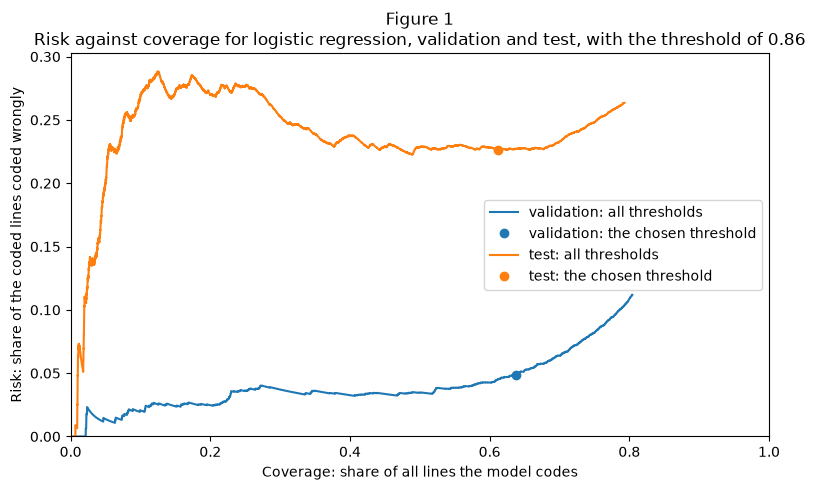

In [66]:
curves = {
    "validation": risk_coverage(truth_val, val_proba[chosen_name]),
    "test": risk_coverage(truth_test, test_proba[chosen_name]),
}
points = {
    name: (
        reject_table.loc[name, "coverage"],
        1 - reject_table.loc[name, "accuracy on the lines the model codes"],
    )
    for name in curves
}
fig = plot_risk_coverage(
    curves,
    points,
    "Figure 1",
    f"Risk against coverage for {chosen_name}, validation and test, with the "
    f"threshold of {threshold:.2f}",
)
fig.savefig(
    OUTPUTS / "figure_1_risk_coverage.png", dpi=150, bbox_inches="tight"
)
plt.show()

**Figure 1.** Each curve traces the risk, the share of the coded lines coded wrongly, as the threshold falls and coverage rises (Geifman & El-Yaniv, 2017). On validation, at the chosen threshold, 0.951 of the coded lines are right at a coverage of 0.637. On test the curve lies above the validation curve at almost every coverage, and at the same threshold only 0.774 of the coded lines are right, at a coverage of 0.613. I read that as the drift: the model's mistakes on test are confident ones, so no threshold set on validation removes them.

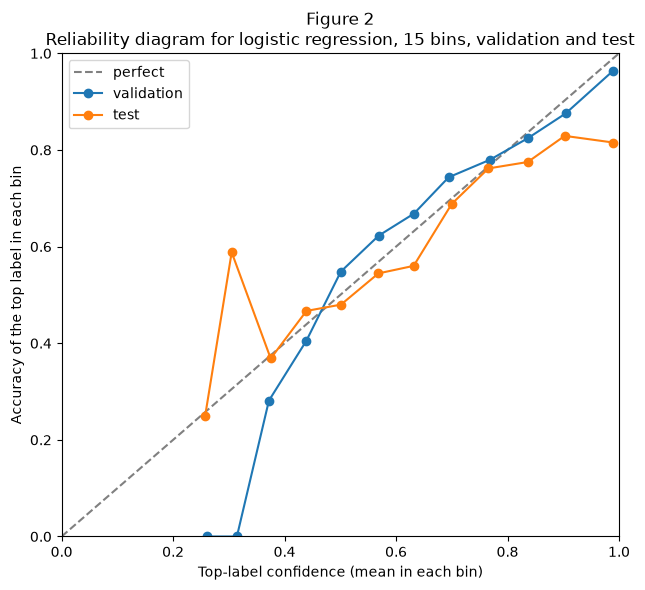

In [67]:
fig = plot_reliability(
    calibration,
    "Figure 2",
    f"Reliability diagram for {chosen_name}, 15 bins, validation and test",
)
fig.savefig(OUTPUTS / "figure_2_reliability.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 2.** On validation the points sit close to the diagonal, with an ECE of 0.028. On test they fall below it at the top: lines the model is 0.990 sure of are right 0.815 of the time, which is most of the test ECE of 0.135 (Guo et al., 2017). I read the model as well calibrated on the months it knows and overconfident once the labels change.

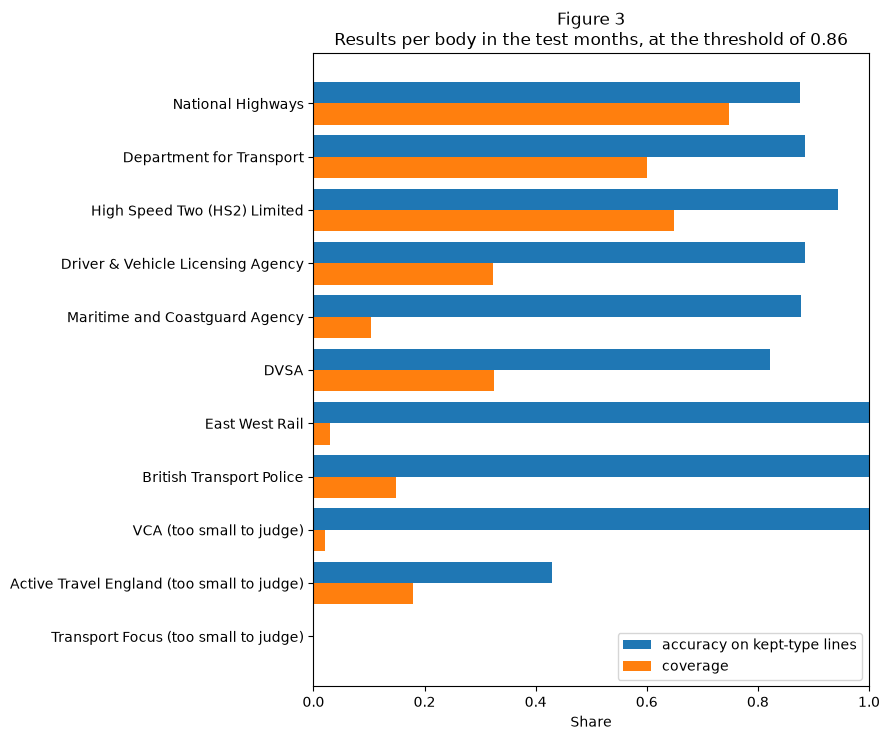

In [68]:
fig = plot_body_results(
    body_results,
    "Figure 3",
    "Results per body in the test months, at the threshold of "
    f"{threshold:.2f}",
)
fig.savefig(OUTPUTS / "figure_3_per_body.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 3.** The bars repeat the results per body. Accuracy on kept-type lines is high for every body large enough to judge, but coverage varies widely: the model codes 0.748 of National Highways' lines and 0.030 of East West Rail's, because under one kept-types list a small body's lines are mostly "Other". What I cannot draw in these bars is National Highways' confident mistakes on its "Other" lines, 0.808 of them given a real type, which the table of results per body shows.

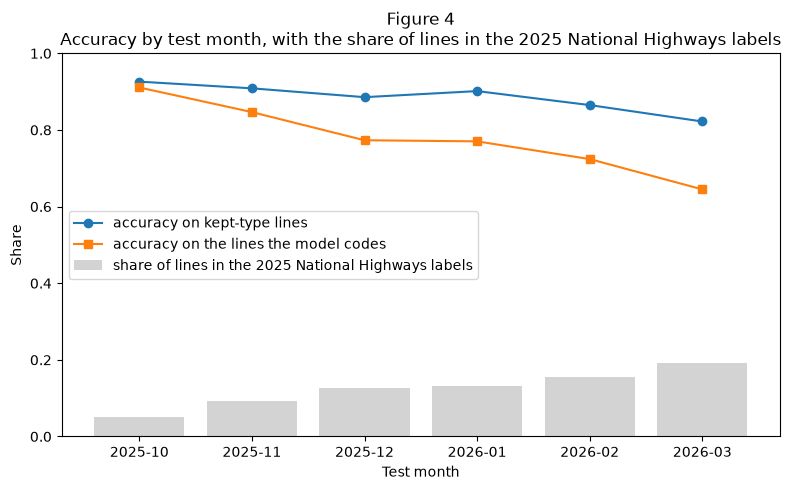

In [69]:
fig = plot_monthly(
    monthly,
    "Figure 4",
    "Accuracy by test month, with the share of lines in the 2025 National "
    "Highways labels",
)
fig.savefig(OUTPUTS / "figure_4_monthly.png", dpi=150, bbox_inches="tight")
plt.show()

**Figure 4.** As the share of lines in the 2025 National Highways labels grows month by month, from 0.051 to 0.193, the accuracy on the lines the model codes falls from 0.911 to 0.645, while the accuracy on kept-type lines falls less, from 0.926 to 0.822. That is the concept drift I found under Evaluation. I read the gap between the two lines as the signature of the new labels: they are "Other", so they hurt the lines the model codes and not the kept-type lines.

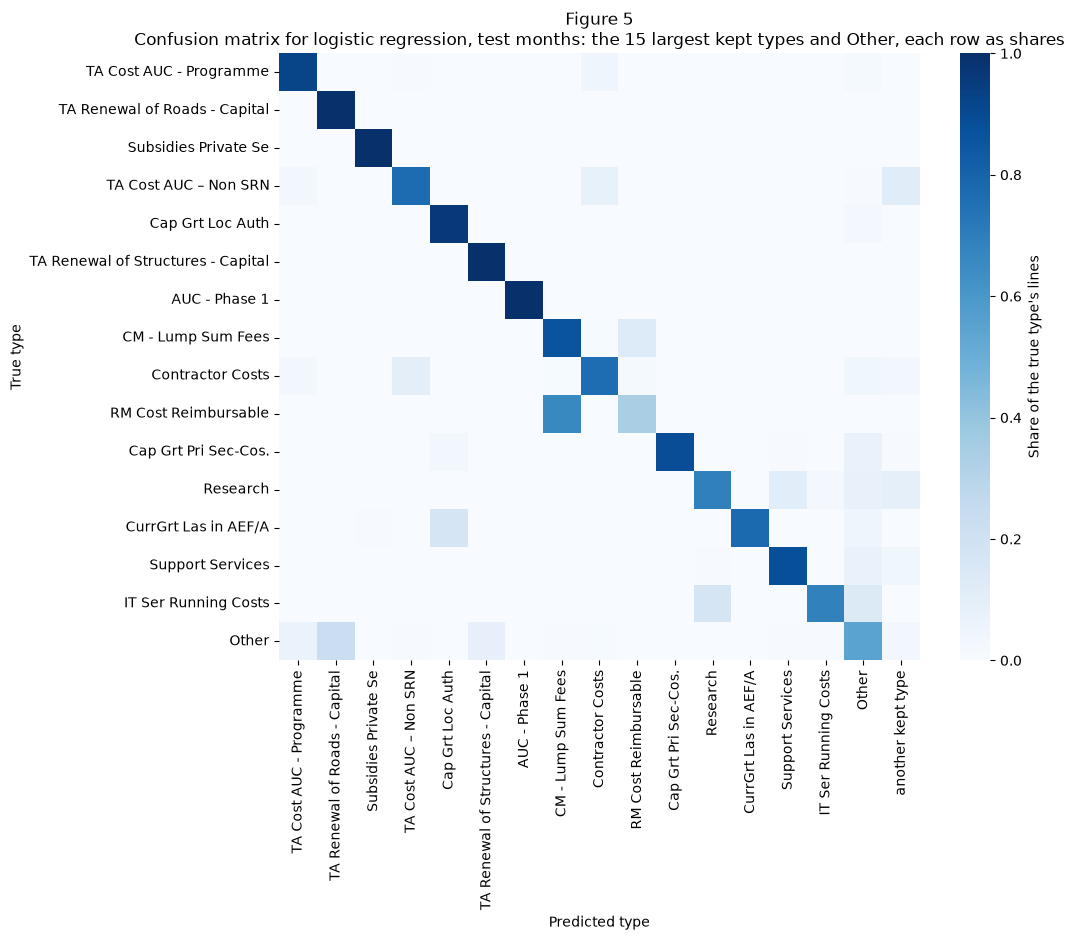

"Other" lines predicted "Other": 0.552
"Other" lines predicted "TA Renewal of Roads - Capital": 0.225
"Other" lines predicted "TA Renewal of Structures - Capital": 0.083
Weakest of the 15: "RM Cost Reimbursable", right on 0.337; most often coded "CM - Lump Sum Fees" (0.660)


In [70]:
largest = truth_test[truth_test != "Other"].value_counts().head(15).index
fig, confusion = plot_confusion(
    truth_test,
    test_pred[chosen_name],
    list(largest) + ["Other"],
    "Figure 5",
    f"Confusion matrix for {chosen_name}, test months: the 15 largest kept "
    "types and Other, each row as shares",
)
fig.savefig(OUTPUTS / "figure_5_confusion.png", dpi=150, bbox_inches="tight")
plt.show()
shown_labels = list(largest) + ["Other"]
hits = pd.Series(
    np.diag(confusion.loc[shown_labels, shown_labels]), index=shown_labels
)
weakest = hits.drop("Other").idxmin()
print(f'"Other" lines predicted "Other": {hits["Other"]:.3f}')
for name, share in confusion.loc["Other"].drop("Other").nlargest(2).items():
    print(f'"Other" lines predicted "{name}": {share:.3f}')
print(
    f'Weakest of the 15: "{weakest}", right on {hits[weakest]:.3f}; most '
    f'often coded "{confusion.loc[weakest].drop(weakest).idxmax()}" '
    f"({confusion.loc[weakest].drop(weakest).max():.3f})"
)

**Figure 5.** For the 15 largest kept types most of each row falls on the diagonal. The "Other" row shows where the costly mistakes go: the model predicts "Other" for 0.552 of the "Other" lines, and the largest shares of the rest go to "TA Renewal of Roads - Capital", 0.225, and "TA Renewal of Structures - Capital", 0.083, the capital accounts the 2025 National Highways labels were coded to. The weakest of the 15 is "RM Cost Reimbursable": the model gets 0.337 of its lines right and codes 0.660 of them as "CM - Lump Sum Fees", so I read those two accounts as hard for it to tell apart.

In [71]:
def model_card(
    model,
    window,
    months,
    lines,
    kept,
    threshold,
    reject,
    primary,
    bodies,
    limits,
    target=0.95,
):
    """Return a short model card in Markdown.

    Its sections follow Mitchell et al. (2019): intended use, the model,
    data, metrics, results per body and limits. None of the inputs is
    changed.

    Parameters
    ----------
    model, window : str
        The chosen model and its training window.
    months : tuple of str
        The window's first and last month.
    lines, kept : int
        The training lines and the number of kept types.
    threshold : float
        The confidence threshold.
    reject : pandas.DataFrame
        From the reject option, indexed by set: coverage and accuracy on
        the lines the model codes.
    primary : pandas.Series
        Accuracy on kept-type lines, indexed by set.
    bodies : pandas.DataFrame
        From results_per_body.
    limits : list of str
        One sentence or two per limit.
    target : float, default 0.95
        The accuracy the threshold was set to reach on validation.

    Returns
    -------
    str
    """
    metric_rows = "\n".join(
        f"| {name} | {primary[name]:.3f} | {row['coverage']:.3f} | "
        f"{row['accuracy on the lines the model codes']:.3f} |"
        for name, row in reject.iterrows()
    )
    body_rows = "\n".join(
        f"| {name} | {row['lines']:,} | "
        + (
            "n/a"
            if np.isnan(row["accuracy on kept-type lines"])
            else f"{row['accuracy on kept-type lines']:.3f}"
        )
        + f" | {row['coverage']:.3f} | {row['judged']} |"
        for name, row in bodies.iterrows()
    )
    limit_rows = "\n".join(f"- {limit}" for limit in limits)
    return (
        "# Model card: suggesting the Expense Type for DfT spend lines\n\n"
        "## Intended use\n\n"
        "To suggest the Expense Type, the general ledger account, for a "
        "Department for Transport spend line over £25,000. The model codes a "
        "line only when its confidence reaches the threshold and leaves "
        "every other line to a person. It is not meant for other bodies' "
        "ledgers, for lines under £25,000, or for coding without a person "
        "reviewing the lines it defers.\n\n"
        "## Model\n\n"
        f"Model: {model}, trained on a window of {window}, {months[0]} to "
        f"{months[1]}, {lines:,} lines, predicting {kept} kept types and "
        f'"Other". Confidence threshold {threshold:.2f}, set on validation '
        f"as the lowest that reaches {target:.0%} accuracy on the lines the "
        "model codes.\n\n"
        "## Data\n\n"
        "DfT's published spend over £25,000, April 2022 to March 2026, under "
        "the Open Government Licence v3.0. A time-ordered hold-out: training "
        "to June 2025, validation July to September 2025, test October 2025 "
        "to March 2026, read once.\n\n"
        "## Metrics\n\n"
        "| set | accuracy on kept-type lines | coverage | accuracy on the "
        "lines the model codes |\n"
        "|---|---|---|---|\n"
        f"{metric_rows}\n\n"
        "## Results per body\n\n"
        "Test months, at the threshold.\n\n"
        "| body | test lines | accuracy on kept-type lines | coverage | "
        "judged |\n"
        "|---|---|---|---|---|\n"
        f"{body_rows}\n\n"
        "## Limits\n\n"
        f"{limit_rows}\n"
    )

In [72]:
LIMITS = [
    "Labels change over time. In the test months the 2025 National Highways "
    "labels took lines from older accounts, and the model coded many of "
    "them confidently as the old accounts. Watch the accuracy on the lines "
    "the model codes each month, and retrain, resetting the threshold, when "
    "a body changes its accounts.",
    "Expense Area is an input on the assumption that it is known before a "
    "line is coded. Without it the model is weaker.",
    "One kept-types list serves every body, so small bodies send most of "
    'their lines to "Other".',
    "The results come from one time-ordered hold-out, so they carry "
    "uncertainty that one test period cannot measure.",
]
card = model_card(
    chosen_name,
    chosen_window,
    (in_window["month"].min(), in_window["month"].max()),
    len(X_train),
    len(kept),
    threshold,
    reject_table,
    metrics_table.loc[chosen_name].loc[PRIMARY],
    body_results,
    LIMITS,
)
(OUTPUTS / "model_card.md").write_text(card, encoding="utf-8")
print(card)

# Model card: suggesting the Expense Type for DfT spend lines

## Intended use

To suggest the Expense Type, the general ledger account, for a Department for Transport spend line over £25,000. The model codes a line only when its confidence reaches the threshold and leaves every other line to a person. It is not meant for other bodies' ledgers, for lines under £25,000, or for coding without a person reviewing the lines it defers.

## Model

Model: logistic regression, trained on a window of 12 months, 2024-07 to 2025-06, 31,462 lines, predicting 50 kept types and "Other". Confidence threshold 0.86, set on validation as the lowest that reaches 95% accuracy on the lines the model codes.

## Data

DfT's published spend over £25,000, April 2022 to March 2026, under the Open Government Licence v3.0. A time-ordered hold-out: training to June 2025, validation July to September 2025, test October 2025 to March 2026, read once.

## Metrics

| set | accuracy on kept-type lines | coverage | accur

**The model card.** It sets out in one place the intended use, the model, the data, the metrics, the results per body and the limits, after Mitchell et al. (2019). I save it beside the figures.

### Findings about the published data

**Findings about the published data, apart from the model.** While listing the anomalies I looked for findings of another kind: practices in the published data, each set against HM Treasury's guidance for publishing spend over £25,000 (HM Treasury, 2017). I report three here. They describe the data as published, every line with content, duplicates included. They are findings about the data, not claims of wrongdoing, because the data cannot show the reasons behind them, and none of them feeds the model.

In [73]:
def redacted_subsidies(
    frame, label="Subsidies Private Se", body="Department for Transport"
):
    """Return one body's lines on one label, and how many are redacted.

    A line is redacted when its supplier contains "redact", in any case.
    Lines are grouped by financial year, April to March, from their month.
    frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per line: body, Expense Type, Supplier, amount and month.
    label : str, default "Subsidies Private Se"
        The Expense Type, compared with its ends trimmed.
    body : str, default "Department for Transport"
        The body.

    Returns
    -------
    pandas.DataFrame
        Indexed by financial year ("2022-23"): label lines, redacted
        lines, redacted share and £ on redacted lines.
    """
    lines = frame[
        (frame["body"] == body) & (frame["Expense Type"].str.strip() == label)
    ]
    redacted = lines["Supplier"].str.contains("redact", case=False)
    start = lines["month"].str[:4].astype(int) - (
        lines["month"].str[5:] < "04"
    )
    year = start.astype(str) + "-" + (start + 1).astype(str).str[2:]
    out = pd.DataFrame(
        {
            "label lines": lines.groupby(year).size(),
            "redacted lines": redacted.groupby(year).sum(),
        }
    )
    out["redacted share"] = out["redacted lines"] / out["label lines"]
    out["£ on redacted lines"] = (
        lines["amount"].where(redacted, 0).groupby(year).sum()
    )
    out.index.name = "financial year"
    return out


def placeholder_payees(frame, pattern):
    """Return, for each body, its lines paid to a placeholder payee.

    A payee is a placeholder when its name, in capitals, matches pattern.
    No payee name is returned. frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per line: body, Supplier, amount and month.
    pattern : str
        A regular expression, in capitals.

    Returns
    -------
    pandas.DataFrame
        Indexed by body, most £ first: lines, £, largest line, first month
        and last month.
    """
    lines = frame[frame["Supplier"].str.upper().str.contains(pattern)]
    groups = lines.groupby("body")
    out = pd.DataFrame(
        {
            "lines": groups.size(),
            "£": groups["amount"].sum(),
            "largest line": groups["amount"].max(),
            "first month": groups["month"].min(),
            "last month": groups["month"].max(),
        }
    )
    return out.sort_values("£", ascending=False)


def family_flows(frame, family):
    """Return the payments from one DfT body to another, payer by payee.

    A line's payee is the body of the first fragment in family that its
    supplier, in capitals, contains. A body paying a name that matches
    itself is not a flow between bodies. frame is not changed.

    Parameters
    ----------
    frame : pandas.DataFrame
        One row per line: body, Supplier and amount.
    family : dict of str to str
        A supplier-name fragment, in capitals, to the body it names.

    Returns
    -------
    pandas.DataFrame
        One row per payer and payee, most £ first: payer, payee, lines, £,
        and payee publishes here, True when the payee is a body in frame.
    """
    upper = frame["Supplier"].str.upper()
    payee = pd.Series(None, index=frame.index, dtype=object)
    for fragment, name in family.items():
        found = payee.isna() & upper.str.contains(fragment, regex=False)
        payee = payee.where(~found, name)
    between = payee.notna() & (payee != frame["body"])
    flows = (
        frame[between]
        .assign(payee=payee[between])
        .groupby(["body", "payee"])["amount"]
        .agg(["size", "sum"])
        .reset_index()
    )
    flows.columns = ["payer", "payee", "lines", "£"]
    flows["payee publishes here"] = flows["payee"].isin(set(frame["body"]))
    return flows.sort_values("£", ascending=False).reset_index(drop=True)

In [74]:
# Every line with content, duplicates included: these findings describe the
# data as published, not the lines the model learned from.
published_lines = data[data["excluded"] != "blank_row"]
total_published = published_lines["amount"].sum()
subsidies = redacted_subsidies(published_lines)
core_redacted = published_lines[
    (published_lines["body"] == "Department for Transport")
    & (published_lines["Expense Type"].str.strip() == "Subsidies Private Se")
    & published_lines["Supplier"].str.contains("redact", case=False)
]
print(
    f'DfT core\'s "Subsidies Private Se" lines: '
    f"{subsidies['redacted lines'].sum():,} of "
    f"{subsidies['label lines'].sum():,} lines redacted, "
    f"£{subsidies['£ on redacted lines'].sum():,.2f}"
)
print(
    "Last month with a redacted payee on the label: "
    f"{core_redacted['month'].max()}"
)
subsidies

DfT core's "Subsidies Private Se" lines: 3,476 of 7,121 lines redacted, £1,141,507,926.89
Last month with a redacted payee on the label: 2024-04


,label lines,redacted lines,redacted share,£ on redacted lines
financial year,,,,
2022-23,1367,1353,0.990,"510,379,063.61"
2023-24,2017,2007,0.995,"598,880,614.30"
2024-25,1923,116,0.060,"32,248,248.98"
2025-26,1814,0,0.00,0.00


**A. Redacted payees on private-sector subsidies.** DfT core redacted the payee on 3,476 of its 7,121 "Subsidies Private Se" lines, worth £1,141,507,926.89. Nearly every line on the label was redacted in 2022-23 and 2023-24, 0.990 and 0.995 of them. The redaction stops after April 2024, and in 2025-26 none of the label's 1,814 lines is redacted. The guidance expects redactions to be few: "Items should not be redacted because of the potential to cause embarrassment." (HM Treasury, 2017, p. 8, para. 2.16), and large commercial payments are "expected to be in the public interest in the vast majority of cases" (HM Treasury, 2017, p. 9, para. 2.17). The data does not say why DfT redacted these payees or why it stopped, and I found no explanation on DfT's collection page or its monthly pages.

In [75]:
placeholder_lines = placeholder_payees(published_lines, placeholders)
print(
    f"Placeholder payees: {placeholder_lines['lines'].sum()} lines, "
    f"£{placeholder_lines['£'].sum():,.2f}"
)
placeholder_lines

Placeholder payees: 56 lines, £8,307,591.37


,lines,£,largest line,first month,last month
body,,,,,
Maritime and Coastguard Agency,44,"5,780,626.47","1,846,960.50",2022-08,2026-03
Department for Transport,4,"2,030,908.24","1,015,036.60",2022-04,2023-05
British Transport Police,7,"436,909.66","227,397.00",2022-10,2025-02
DVSA,1,"59,147.00","59,147.00",2023-10,2023-10


**B. Placeholder payees.** 56 lines worth £8,307,591.37 go to payees named only as a placeholder, such as a "one time" or "one off" vendor, at four bodies, and the Maritime and Coastguard Agency holds 44 of them. The guidance asks for "the name of the supplier as per your vendor record" (HM Treasury, 2017, p. 7, para. 2.13), and gives the field's purpose as "To identify the recipient of the spend" (HM Treasury, 2017, p. 12, table 3.1). A one-time vendor record meets the letter of the first but does not show who was paid. I cannot tell from the data whether any of these payees is a person, whose name could rightly be withheld.

In [76]:
# Supplier-name fragments for DfT's bodies on GOV.UK. HS2 Ltd is matched on
# its full name, because contractors' joint ventures put "HS2" in theirs.
FAMILY = {
    "NETWORK RAIL": "Network Rail",
    "NATIONAL HIGHWAYS": "National Highways",
    "HIGH SPEED TWO (HS2) L": "High Speed Two (HS2) Limited",
    "HIGH SPEED 2 (HS2) L": "High Speed Two (HS2) Limited",
    "DRIVER AND VEHICLE STANDARDS": "DVSA",
    "DVSA": "DVSA",
    "DRIVER AND VEHICLE LICENSING": "Driver & Vehicle Licensing Agency",
    "DVLA": "Driver & Vehicle Licensing Agency",
    "MARITIME AND COASTGUARD": "Maritime and Coastguard Agency",
    "BRITISH TRANSPORT POLICE": "British Transport Police",
    "EAST WEST RAIL": "East West Rail",
    "ACTIVE TRAVEL ENGLAND": "Active Travel England",
    "TRANSPORT FOCUS": "Transport Focus",
    "VEHICLE CERTIFICATION": "VCA",
    "CROSSRAIL INTERNATIONAL": "Crossrail International",
    "CIVIL AVIATION AUTHORITY": "Civil Aviation Authority",
    "TRINITY HOUSE": "Trinity House",
    "NORTHERN LIGHTHOUSE": "Northern Lighthouse Board",
    "OFFICE OF RAIL AND ROAD": "Office of Rail and Road",
    "DEPARTMENT FOR TRANSPORT": "Department for Transport",
}
flows = family_flows(published_lines, FAMILY)
inside = flows["£"].sum()
publishing = flows[flows["payee publishes here"]]
# A transfer can reappear in the files only up to what the receiving body
# spends in them, so the overlap is at most the smaller of the two.
inflow = publishing.groupby("payee")["£"].sum()
own = published_lines.groupby("body")["amount"].sum()
overlap = pd.concat([inflow, own[inflow.index]], axis=1).min(axis=1).sum()
print(
    f"Lines from one DfT body to another: {flows['lines'].sum():,}, "
    f"£{inside:,.2f} ({inside / total_published:.1%})"
)
print(
    f"  to bodies whose own spending is in these files: "
    f"{publishing['lines'].sum():,} lines, £{publishing['£'].sum():,.2f}"
)
print(
    f"  counted twice in a simple sum: at most £{overlap:,.2f} "
    f"({overlap / total_published:.1%} of the published total)"
)
hs2_paid = flows[
    (flows["payer"] == "Department for Transport")
    & (flows["payee"] == "High Speed Two (HS2) Limited")
]
print(
    f"DfT core lines paid to HS2 Ltd under any HS2 name: "
    f"{hs2_paid['lines'].sum():,}, £{hs2_paid['£'].sum():,.2f}"
)
# DfT core's grant labels are the ones naming grant in aid or NDPBs.
core = published_lines[published_lines["body"] == "Department for Transport"]
to_hs2 = (
    core["Supplier"]
    .str.upper()
    .str.contains(
        r"HIGH SPEED TWO \(HS2\) L|HIGH SPEED 2 \(HS2\) L", regex=True
    )
)
grant = core["Expense Type"].str.contains("NDPB|Aid", case=False)
print(f"  of them on DfT core's grant labels: {(to_hs2 & grant).sum()}")
flows.head(10)

Lines from one DfT body to another: 3,256, £60,094,071,329.65 (33.9%)
  to bodies whose own spending is in these files: 703 lines, £20,122,854,117.03
  counted twice in a simple sum: at most £17,351,698,411.98 (9.8% of the published total)
DfT core lines paid to HS2 Ltd under any HS2 name: 66, £41,142,639.09
  of them on DfT core's grant labels: 0


,payer,payee,lines,£,payee publishes here
0,Department for Transport,Network Rail,209,"38,865,507,082.78",False
1,Department for Transport,National Highways,75,"19,953,154,737.48",True
2,High Speed Two (HS2) Limited,Network Rail,1455,"874,042,706.48",False
3,Department for Transport,Civil Aviation Authority,477,"171,017,291.02",False
4,Department for Transport,High Speed Two (HS2) Limited,66,"41,142,639.09",True
5,Driver & Vehicle Licensing Agency,Department for Transport,75,"34,783,348.02",True
6,DVSA,Department for Transport,84,"23,253,547.31",True
7,National Highways,Network Rail,197,"20,928,936.49",False
8,High Speed Two (HS2) Limited,Department for Transport,52,"19,135,856.31",True
9,Department for Transport,Office of Rail and Road,28,"14,413,502.85",False


**C. Spend inside the DfT family.** 3,256 lines worth £60,094,071,329.65, 33.9% of all published value, are payments from one DfT body to another. I matched payees by name to the bodies GOV.UK lists as DfT's, and the matching may miss a variant. Most of it is DfT core's funding of Network Rail and National Highways. 703 of the lines, £20,122,854,117.03, go to bodies whose own spending is also in these files, so a simple sum of the files counts the grant and then the spending it pays for: at most £17,351,698,411.98, 9.8% of the published total. The guidance asks for these payments to be published: "transactions with other government departments or public bodies should also be included" (HM Treasury, 2017, p. 5, para. 2.7). So this is a caveat on using the files, not a breach. Separately, none of DfT core's 66 lines to HS2 Ltd is on its grant labels, so no grant to HS2 Ltd appears in the files under any HS2 name.

I assessed these payments between DfT bodies, and their effect on budget totals is a consideration outside the scope of this work.

## Summary

TO WRITE: summary, 4 to 6 sentences, drafted by the main session for Paddy